# Explainable Cataract Detection Using ODIR

## 1. Environment and Project Setup

Verify the Python environment, GPU availability and project folders.
The task is binary classification: cataract versus non-cataract.

In [2]:
from pathlib import Path
import sys

import torch
import torchvision
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name != "cataract-detection-odir":
    raise RuntimeError(
        f"Unexpected working folder: {PROJECT_ROOT}\n"
        "Open the cataract-detection-odir folder in VS Code "
        "and keep this notebook in its main folder."
    )

for relative_path in [
    "data/raw/odir",
    "data/processed",
    "data/splits",
    "models",
    "results",
    "docs",
]:
    (PROJECT_ROOT / relative_path).mkdir(
        parents=True, exist_ok=True
    )

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Project:", PROJECT_ROOT)
print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("Device:", DEVICE)

if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

print("\nProject folders ready.")

Project: C:\Users\Lenovo\OneDrive\Desktop\cataract-detection-odir
Python: c:\Users\Lenovo\OneDrive\Desktop\cataract-detection-odir\.venv\Scripts\python.exe
PyTorch: 2.7.1+cu118
Torchvision: 0.22.1+cu118
NumPy: 2.5.4
pandas: 3.1.0
Device: cuda
GPU: NVIDIA GeForce RTX 3060 Laptop GPU

Project folders ready.


## 2. Dataset Inventory and Annotation Inspection

Identify image folders and annotation files, then inspect annotation
columns before defining eye-level cataract labels and patient groups.

In [3]:
from collections import Counter
from pathlib import Path
import pandas as pd

ODIR_RAW_DIR = PROJECT_ROOT / "data" / "raw" / "odir"

if not ODIR_RAW_DIR.is_dir():
    raise FileNotFoundError(f"Dataset folder not found: {ODIR_RAW_DIR}")

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"
}
ANNOTATION_EXTENSIONS = {".csv", ".xlsx", ".xls"}

image_folder_counts = Counter()
annotation_paths = []

# Inventory only: no images are modified or combined.
for path in ODIR_RAW_DIR.rglob("*"):
    if not path.is_file():
        continue

    extension = path.suffix.lower()

    if extension in IMAGE_EXTENSIONS:
        folder = path.parent.relative_to(ODIR_RAW_DIR).as_posix()
        image_folder_counts[folder] += 1

    elif extension in ANNOTATION_EXTENSIONS:
        if not path.name.startswith("~$"):
            annotation_paths.append(path)

print("DATASET LOCATION")
print(ODIR_RAW_DIR)

print("\nIMAGE FILES BY FOLDER")
for folder, count in sorted(image_folder_counts.items()):
    print(f"{folder}: {count:,}")

print(
    "\nTotal image files:",
    f"{sum(image_folder_counts.values()):,}",
    "(not necessarily unique images or patients)"
)

print("\nANNOTATION FILES")
for path in sorted(annotation_paths):
    print(path.relative_to(ODIR_RAW_DIR))

# Store tables for later inspection without displaying patient rows.
annotation_tables = {}

for path in sorted(annotation_paths):
    relative_name = path.relative_to(ODIR_RAW_DIR).as_posix()

    try:
        if path.suffix.lower() == ".csv":
            tables = {
                relative_name: pd.read_csv(path, low_memory=False)
            }
        else:
            sheets = pd.read_excel(path, sheet_name=None)
            tables = {
                f"{relative_name} | sheet={sheet_name}": table
                for sheet_name, table in sheets.items()
            }

        for table_name, table in tables.items():
            annotation_tables[table_name] = table

            print(f"\nTABLE: {table_name}")
            print(f"Rows: {len(table):,} | Columns: {len(table.columns)}")
            print("Column names:")
            for column in table.columns:
                print(f"  - {column}")

    except Exception as error:
        print(f"\nCould not read {relative_name}: {error}")

print("\nInventory complete. No labels or splits created yet.")

DATASET LOCATION
C:\Users\Lenovo\OneDrive\Desktop\cataract-detection-odir\data\raw\odir

IMAGE FILES BY FOLDER
ODIR-5K/ODIR-5K/Testing Images: 1,000
ODIR-5K/ODIR-5K/Training Images: 7,000
preprocessed_images: 6,392

Total image files: 14,392 (not necessarily unique images or patients)

ANNOTATION FILES
full_df.csv
ODIR-5K\ODIR-5K\data.xlsx

TABLE: full_df.csv
Rows: 6,392 | Columns: 19
Column names:
  - ID
  - Patient Age
  - Patient Sex
  - Left-Fundus
  - Right-Fundus
  - Left-Diagnostic Keywords
  - Right-Diagnostic Keywords
  - N
  - D
  - G
  - C
  - A
  - H
  - M
  - O
  - filepath
  - labels
  - target
  - filename

TABLE: ODIR-5K/ODIR-5K/data.xlsx | sheet=Sheet1
Rows: 3,500 | Columns: 15
Column names:
  - ID
  - Patient Age
  - Patient Sex
  - Left-Fundus
  - Right-Fundus
  - Left-Diagnostic Keywords
  - Right-Diagnostic Keywords
  - N
  - D
  - G
  - C
  - A
  - H
  - M
  - O

Inventory complete. No labels or splits created yet.


## 3. Patient Records and Eye-Level Annotation Audit

Inspect the original patient spreadsheet and create an annotation
table with one row per eye. Examine diagnostic keywords before
defining binary labels. Patient-level disease indicators will
not automatically be applied to both eyes.

In [4]:
import pandas as pd

REQUIRED_COLUMNS = {
    "ID",
    "Left-Fundus",
    "Right-Fundus",
    "Left-Diagnostic Keywords",
    "Right-Diagnostic Keywords",
}

if "annotation_tables" not in globals():
    raise RuntimeError("Run Section 2 first.")

print("ANNOTATION TABLE COMPARISON")

spreadsheet_candidates = []

for name, table in annotation_tables.items():
    print(f"\n{name}")
    print("Rows:", len(table))

    if "ID" in table.columns:
        print("Unique non-missing IDs:", table["ID"].nunique())
        print("Missing IDs:", table["ID"].isna().sum())
        print(
            "Rows with repeated IDs:",
            table["ID"].duplicated(keep=False).sum()
        )

    is_spreadsheet = (
        ".xlsx | sheet=" in name.lower()
        or ".xls | sheet=" in name.lower()
    )

    if is_spreadsheet and REQUIRED_COLUMNS.issubset(table.columns):
        spreadsheet_candidates.append(name)

if len(spreadsheet_candidates) != 1:
    raise RuntimeError(
        "Expected exactly one original spreadsheet sheet with "
        "the required columns. Share this output before continuing.\n"
        f"Candidates: {spreadsheet_candidates}"
    )

SOURCE_TABLE_NAME = spreadsheet_candidates[0]

# Remove only completely identical records.
source_table = annotation_tables[SOURCE_TABLE_NAME]
patient_annotations = source_table.drop_duplicates().copy()

print("\nSELECTED SOURCE:", SOURCE_TABLE_NAME)
print(
    "Completely identical rows removed:",
    len(source_table) - len(patient_annotations)
)

if patient_annotations["ID"].isna().any():
    raise ValueError("Missing patient IDs require inspection.")

# Normalise the grouping key without displaying individual IDs.
patient_annotations["patient_id"] = (
    patient_annotations["ID"]
    .astype("string")
    .str.strip()
)

if patient_annotations["patient_id"].eq("").any():
    raise ValueError("Empty patient IDs require inspection.")

if patient_annotations["patient_id"].duplicated().any():
    raise ValueError(
        "Multiple non-identical records share a patient ID. "
        "Inspect them before creating eye-level records."
    )

eye_tables = []

for eye_side, filename_column, keyword_column in [
    ("left", "Left-Fundus", "Left-Diagnostic Keywords"),
    ("right", "Right-Fundus", "Right-Diagnostic Keywords"),
]:
    eye_table = patient_annotations[
        ["patient_id", filename_column, keyword_column]
    ].copy()

    eye_table.columns = [
        "patient_id", "filename", "diagnostic_keywords"
    ]
    eye_table["eye_side"] = eye_side
    eye_tables.append(eye_table)

eye_annotations = pd.concat(eye_tables, ignore_index=True)

eye_annotations["filename"] = (
    eye_annotations["filename"]
    .astype("string")
    .fillna("")
    .str.strip()
)

eye_annotations["diagnostic_keywords"] = (
    eye_annotations["diagnostic_keywords"]
    .astype("string")
    .fillna("")
    .str.normalize("NFKC")
    .str.strip()
    .str.casefold()
)

print("\nEYE-LEVEL ANNOTATION SUMMARY")
print("Patient groups:", eye_annotations["patient_id"].nunique())
print("Eye records:", len(eye_annotations))
print("Missing filenames:", eye_annotations["filename"].eq("").sum())
print(
    "Missing diagnostic keywords:",
    eye_annotations["diagnostic_keywords"].eq("").sum()
)

keyword_counts = (
    eye_annotations["diagnostic_keywords"]
    .value_counts()
    .rename_axis("diagnostic_keywords")
    .reset_index(name="eye_records")
)

print("\nMOST FREQUENT DIAGNOSTIC KEYWORD STRINGS")
print(keyword_counts.head(20).to_string(index=False))

print("\nKEYWORD STRINGS CONTAINING 'CATARACT'")
cataract_keyword_counts = keyword_counts[
    keyword_counts["diagnostic_keywords"].str.contains(
        "cataract", regex=False, na=False
    )
]
print(cataract_keyword_counts.to_string(index=False))

print("\nAudit complete. Binary labels and splits are not yet assigned.")

ANNOTATION TABLE COMPARISON

full_df.csv
Rows: 6392
Unique non-missing IDs: 3358
Missing IDs: 0
Rows with repeated IDs: 6068

ODIR-5K/ODIR-5K/data.xlsx | sheet=Sheet1
Rows: 3500
Unique non-missing IDs: 3500
Missing IDs: 0
Rows with repeated IDs: 0

SELECTED SOURCE: ODIR-5K/ODIR-5K/data.xlsx | sheet=Sheet1
Completely identical rows removed: 0

EYE-LEVEL ANNOTATION SUMMARY
Patient groups: 3500
Eye records: 7000
Missing filenames: 0
Missing diagnostic keywords: 0

MOST FREQUENT DIAGNOSTIC KEYWORD STRINGS
                                            diagnostic_keywords  eye_records
                                                  normal fundus         2816
                         moderate non proliferative retinopathy          745
                              mild nonproliferative retinopathy          460
                                                       cataract          262
                                            pathological myopia          227
                               

## 4. Image Matching and Diagnostic Vocabulary Review

Match eye annotations to original image files, excluding preprocessed
copies. Review diagnostic terms before defining cataract positives,
non-cataract negatives and exclusions.

In [5]:
from collections import defaultdict
from pathlib import Path

ORIGINAL_ROOT = ODIR_RAW_DIR / "ODIR-5K" / "ODIR-5K"

original_folders = {
    "original_training": ORIGINAL_ROOT / "Training Images",
    "original_testing": ORIGINAL_ROOT / "Testing Images",
}

image_index = defaultdict(list)

for source_name, folder in original_folders.items():
    if not folder.is_dir():
        raise FileNotFoundError(f"Missing image folder: {folder}")

    for path in folder.rglob("*"):
        if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS:
            image_index[path.name.casefold()].append(
                (source_name, path)
            )

eye_manifest = eye_annotations.copy()

def find_image(filename):
    # Support annotations containing either filenames or paths.
    basename = str(filename).replace("\\", "/").split("/")[-1]
    matches = image_index.get(basename.casefold(), [])

    if len(matches) == 1:
        source_name, path = matches[0]
        return {
            "match_status": "matched",
            "image_source": source_name,
            "image_path": path.relative_to(PROJECT_ROOT).as_posix(),
        }

    return {
        "match_status": "missing" if not matches else "ambiguous",
        "image_source": "",
        "image_path": "",
    }

match_details = pd.DataFrame(
    [find_image(name) for name in eye_manifest["filename"]]
)

eye_manifest = pd.concat(
    [eye_manifest.reset_index(drop=True), match_details],
    axis=1,
)

print("IMAGE MATCHING")
print(eye_manifest["match_status"].value_counts().to_string())

print("\nMATCHED IMAGE SOURCES")
print(
    eye_manifest.loc[
        eye_manifest["match_status"].eq("matched"),
        "image_source"
    ].value_counts().to_string()
)

matched_paths = eye_manifest.loc[
    eye_manifest["match_status"].eq("matched"), "image_path"
]

print(
    "\nRepeated matched image paths:",
    matched_paths.duplicated(keep=False).sum()
)

if not eye_manifest["match_status"].eq("matched").all():
    raise RuntimeError(
        "Some image matches need investigation. "
        "Share this output before continuing."
    )

if matched_paths.duplicated().any():
    raise RuntimeError(
        "An image is referenced more than once. "
        "Investigate before creating splits."
    )

print("\nAll eye records matched to distinct original image paths.")

IMAGE MATCHING
match_status
matched    7000

MATCHED IMAGE SOURCES
image_source
original_training    7000

Repeated matched image paths: 0

All eye records matched to distinct original image paths.


In [6]:
# Separate comma/semicolon-delimited diagnostic terms.
diagnostic_tokens = (
    eye_manifest["diagnostic_keywords"]
    .str.split(r"[,;；|]+", regex=True)
    .explode()
    .str.strip()
)

diagnostic_tokens = diagnostic_tokens[
    diagnostic_tokens.notna() & diagnostic_tokens.ne("")
]

token_counts = (
    diagnostic_tokens.value_counts()
    .rename_axis("diagnostic_term")
    .reset_index(name="eye_records")
)

AUDIT_DIR = PROJECT_ROOT / "results" / "data_audit"
AUDIT_DIR.mkdir(parents=True, exist_ok=True)

token_counts.to_csv(
    AUDIT_DIR / "diagnostic_term_counts.csv",
    index=False,
)

print("MOST FREQUENT TERMS")
print(token_counts.head(15).to_string(index=False))

review_mask = token_counts["diagnostic_term"].str.contains(
    r"cataract|lens|pseudoph|aphak|opacity|opaque|"
    r"blur|quality|ungradable|suspect|possible",
    case=False,
    regex=True,
    na=False,
)

print("\nTERMS REQUIRING LABEL OR EXCLUSION REVIEW")
print(token_counts.loc[review_mask].to_string(index=False))

print("\nComplete vocabulary saved to:")
print(AUDIT_DIR / "diagnostic_term_counts.csv")

MOST FREQUENT TERMS
                       diagnostic_term  eye_records
                         normal fundus         3100
moderate non proliferative retinopathy          997
     mild nonproliferative retinopathy          552
                             lens dust          408
                              cataract          313
                              glaucoma          282
                   pathological myopia          246
  dry age-related macular degeneration          228
           macular epiretinal membrane          201
              hypertensive retinopathy          193
                   epiretinal membrane          187
                                drusen          180
   severe nonproliferative retinopathy          161
               myelinated nerve fibers           99
                            laser spot           95

TERMS REQUIRING LABEL OR EXCLUSION REVIEW
                                 diagnostic_term  eye_records
                                       lens

## 5. Binary Labels and Eligibility Rules

Define cataract presence using exact eye-level diagnostic terms.

Labels:
- 0: Non-cataract recorded
- 1: Cataract recorded

Retain healthy and other-condition negative subgroups for evaluation.
Apply predefined exclusions before splitting. Save included and
excluded records with reasons so cohort construction is reproducible.

In [7]:
import re
import pandas as pd

CLASS_NAMES = ["Non-cataract", "Cataract"]

# Operational exclusions for this initial study.
QUALITY_EXCLUSION_TERMS = {
    "lens dust",
    "low image quality",
    "optic disk photographically invisible",
    "anterior segment image",
    "image offset",
    "no fundus image",
}

def split_diagnostic_terms(text):
    return {
        re.sub(r"\s+", " ", term.strip().casefold())
        for term in re.split(r"[,;；|]+", str(text))
        if term.strip()
    }

label_audit = eye_manifest.copy()
label_audit["diagnostic_terms"] = (
    label_audit["diagnostic_keywords"].map(split_diagnostic_terms)
)

def assign_detection_label(terms):
    reasons = []

    if not terms:
        reasons.append("missing_diagnostic_terms")

    quality_terms = terms & QUALITY_EXCLUSION_TERMS
    if quality_terms:
        reasons.append(
            "quality_or_image_issue: " + ", ".join(sorted(quality_terms))
        )

    # Do not treat suspected/modified cataract descriptions as negatives.
    uncertain_cataract = {
        term for term in terms
        if "cataract" in term and term != "cataract"
    }
    if uncertain_cataract:
        reasons.append("uncertain_cataract_annotation")

    has_cataract = "cataract" in terms

    if "refractive media opacity" in terms and not has_cataract:
        reasons.append("media_opacity_without_explicit_cataract")

    if "silicone oil eye" in terms:
        reasons.append("excluded_altered_eye_state")

    if has_cataract and "normal fundus" in terms:
        reasons.append("normal_and_cataract_annotation_conflict")

    if reasons:
        return {
            "label": pd.NA,
            "evaluation_group": "excluded",
            "exclusion_reason": "; ".join(reasons),
        }

    if has_cataract:
        return {
            "label": 1,
            "evaluation_group": "cataract",
            "exclusion_reason": "",
        }

    return {
        "label": 0,
        "evaluation_group": (
            "healthy_negative"
            if terms == {"normal fundus"}
            else "other_condition_negative"
        ),
        "exclusion_reason": "",
    }

assigned_labels = pd.DataFrame(
    [
        assign_detection_label(terms)
        for terms in label_audit["diagnostic_terms"]
    ],
    index=label_audit.index,
)

label_audit = pd.concat([label_audit, assigned_labels], axis=1)
label_audit["label"] = label_audit["label"].astype("Int64")

# One row per included eye; both eyes will remain grouped by patient.
detection_manifest = label_audit.loc[
    label_audit["label"].notna()
].copy()

detection_manifest["label"] = (
    detection_manifest["label"].astype("int64")
)

excluded_manifest = label_audit.loc[
    label_audit["label"].isna()
].copy()

print("ELIGIBLE COHORT")
print(
    detection_manifest.groupby("evaluation_group").agg(
        images=("filename", "size"),
        patients=("patient_id", "nunique"),
    ).to_string()
)

print("\nBINARY CLASS COUNTS")
for label, name in enumerate(CLASS_NAMES):
    count = detection_manifest["label"].eq(label).sum()
    print(f"{label} — {name}: {count:,}")

print("\nExcluded images:", len(excluded_manifest))
print(
    "Explicit cataract images before exclusions:",
    label_audit["diagnostic_terms"].map(
        lambda terms: "cataract" in terms
    ).sum()
)
print(
    "Explicit cataract images retained:",
    detection_manifest["label"].eq(1).sum()
)

ELIGIBLE COHORT
                          images  patients
evaluation_group                          
cataract                     287       196
healthy_negative            2818      1816
other_condition_negative    3395      2110

BINARY CLASS COUNTS
0 — Non-cataract: 6,213
1 — Cataract: 287

Excluded images: 500
Explicit cataract images before exclusions: 313
Explicit cataract images retained: 287


In [8]:
import json

MANIFEST_DIR = PROJECT_ROOT / "data" / "processed"
MANIFEST_DIR.mkdir(parents=True, exist_ok=True)
AUDIT_DIR.mkdir(parents=True, exist_ok=True)

# Convert sets to stable text for CSV storage.
def serialise_manifest(table):
    saved = table.copy()
    saved["diagnostic_terms"] = saved["diagnostic_terms"].map(
        lambda terms: "; ".join(sorted(terms))
    )
    return saved

serialise_manifest(detection_manifest).to_csv(
    MANIFEST_DIR / "detection_manifest.csv",
    index=False,
)

serialise_manifest(excluded_manifest).to_csv(
    MANIFEST_DIR / "excluded_manifest.csv",
    index=False,
)

exclusion_counts = (
    excluded_manifest["exclusion_reason"]
    .value_counts()
    .rename_axis("exclusion_reason")
    .reset_index(name="images")
)

exclusion_counts.to_csv(
    AUDIT_DIR / "exclusion_counts.csv",
    index=False,
)

label_protocol = {
    "annotation_source": SOURCE_TABLE_NAME,
    "class_names": CLASS_NAMES,
    "positive_rule": "Exact cataract diagnostic token",
    "negative_interpretation": "No cataract recorded; not clinical confirmation",
    "healthy_negative_rule": "Only normal fundus token",
    "quality_exclusion_terms": sorted(QUALITY_EXCLUSION_TERMS),
    "other_exclusions": [
        "Uncertain or modified cataract terms",
        "Refractive media opacity without explicit cataract",
        "Silicone oil eye",
        "Normal fundus and cataract in the same eye annotation",
        "Missing diagnostic terms",
    ],
    "splits_created": False,
}

(AUDIT_DIR / "label_protocol.json").write_text(
    json.dumps(label_protocol, indent=2),
    encoding="utf-8",
)

print("EXCLUSION COUNTS")
print(exclusion_counts.to_string(index=False))
print("\nManifests saved in:", MANIFEST_DIR)
print("Label protocol saved in:", AUDIT_DIR)
print("\nNo training, validation or test split created yet.")

EXCLUSION COUNTS
                                             exclusion_reason  images
                            quality_or_image_issue: lens dust     405
                      media_opacity_without_explicit_cataract      63
                    quality_or_image_issue: low image quality      21
quality_or_image_issue: optic disk photographically invisible       5
               quality_or_image_issue: anterior segment image       2
                                   excluded_altered_eye_state       1
                         quality_or_image_issue: image offset       1
                      quality_or_image_issue: no fundus image       1
                                uncertain_cataract_annotation       1

Manifests saved in: C:\Users\Lenovo\OneDrive\Desktop\cataract-detection-odir\data\processed
Label protocol saved in: C:\Users\Lenovo\OneDrive\Desktop\cataract-detection-odir\results\data_audit

No training, validation or test split created yet.


## 6. Image Integrity and Duplicate Checks

Decode every eligible image and record its dimensions.
Compute a hash of the decoded RGB pixels to identify exact duplicates.

Also record a perceptual fingerprint for a later near-duplicate review.
Original dataset files are not modified.

In [9]:
import hashlib
import numpy as np
import pandas as pd
from PIL import Image, ImageOps

def inspect_image(relative_path):
    image_path = PROJECT_ROOT / relative_path

    try:
        with Image.open(image_path) as original:
            rgb = ImageOps.exif_transpose(original).convert("RGB")
            rgb.load()

            width, height = rgb.size

            # Include dimensions so equal bytes with different shapes
            # cannot be treated as the same image.
            pixel_hasher = hashlib.sha256()
            pixel_hasher.update(
                f"RGB:{width}:{height}:".encode("utf-8")
            )
            pixel_hasher.update(rgb.tobytes())

            # Difference hash: a fingerprint for later candidate review.
            small = rgb.convert("L").resize(
                (9, 8), Image.Resampling.BILINEAR
            )
            small_array = np.asarray(small)
            differences = (
                small_array[:, 1:] > small_array[:, :-1]
            ).flatten()

            difference_hash = 0
            for bit in differences:
                difference_hash = (
                    difference_hash << 1
                ) | int(bit)

        return {
            "image_path": relative_path,
            "image_status": "ok",
            "width": width,
            "height": height,
            "pixel_sha256": pixel_hasher.hexdigest(),
            "dhash": f"{difference_hash:016x}",
            "image_error": "",
        }

    except Exception as error:
        return {
            "image_path": relative_path,
            "image_status": "unreadable",
            "width": None,
            "height": None,
            "pixel_sha256": "",
            "dhash": "",
            "image_error": f"{type(error).__name__}: {error}",
        }

integrity_records = []
total_images = len(detection_manifest)

for number, relative_path in enumerate(
    detection_manifest["image_path"], start=1
):
    integrity_records.append(inspect_image(relative_path))

    if number % 500 == 0 or number == total_images:
        print(f"Checked {number:,}/{total_images:,} images")

image_integrity = pd.DataFrame(integrity_records)

image_integrity.to_csv(
    AUDIT_DIR / "image_integrity.csv",
    index=False,
)

print("\nImage inspection complete.")

Checked 500/6,500 images
Checked 1,000/6,500 images
Checked 1,500/6,500 images
Checked 2,000/6,500 images
Checked 2,500/6,500 images
Checked 3,000/6,500 images
Checked 3,500/6,500 images
Checked 4,000/6,500 images
Checked 4,500/6,500 images
Checked 5,000/6,500 images
Checked 5,500/6,500 images
Checked 6,000/6,500 images
Checked 6,500/6,500 images

Image inspection complete.


In [10]:
audited_manifest = detection_manifest.merge(
    image_integrity,
    on="image_path",
    how="left",
    validate="one_to_one",
)

print("IMAGE READABILITY")
print(audited_manifest["image_status"].value_counts().to_string())

# This is an intermediate table, not the final training cohort.
verified_manifest = audited_manifest.loc[
    audited_manifest["image_status"].eq("ok")
].copy()

unreadable_manifest = audited_manifest.loc[
    ~audited_manifest["image_status"].eq("ok")
].copy()

exact_duplicate_rows = verified_manifest.loc[
    verified_manifest["pixel_sha256"].duplicated(keep=False)
].copy()

duplicate_groups = (
    exact_duplicate_rows.groupby("pixel_sha256").agg(
        images=("image_path", "size"),
        patient_groups=("patient_id", "nunique"),
        distinct_labels=("label", "nunique"),
    )
)

print("\nIMAGE DIMENSIONS")
print(
    verified_manifest[["width", "height"]]
    .agg(["min", "median", "max"])
    .to_string()
)

print("\nEXACT DUPLICATES")
print("Duplicate groups:", len(duplicate_groups))
print("Images in duplicate groups:", len(exact_duplicate_rows))
print(
    "Groups spanning different patient IDs:",
    duplicate_groups["patient_groups"].gt(1).sum()
)
print(
    "Groups with conflicting binary labels:",
    duplicate_groups["distinct_labels"].gt(1).sum()
)

# Save records for investigation without changing the source files.
unreadable_manifest.to_csv(
    AUDIT_DIR / "unreadable_images.csv",
    index=False,
)
exact_duplicate_rows.to_csv(
    AUDIT_DIR / "exact_duplicate_images.csv",
    index=False,
)
duplicate_groups.to_csv(
    AUDIT_DIR / "exact_duplicate_groups.csv",
)

serialise_manifest(audited_manifest).to_csv(
    MANIFEST_DIR / "audited_detection_manifest.csv",
    index=False,
)

print("\nAudit files saved:", AUDIT_DIR)
print("No duplicates removed and no splits created yet.")
print("Near-duplicate review is still pending.")

IMAGE READABILITY
image_status
ok    6500

IMAGE DIMENSIONS
         width  height
min      250.0   188.0
median  2592.0  1728.0
max     5184.0  3456.0

EXACT DUPLICATES
Duplicate groups: 0
Images in duplicate groups: 0
Groups spanning different patient IDs: 0
Groups with conflicting binary labels: 0

Audit files saved: C:\Users\Lenovo\OneDrive\Desktop\cataract-detection-odir\results\data_audit
No duplicates removed and no splits created yet.
Near-duplicate review is still pending.


## 7. Near-Duplicate Screening

Compare perceptual fingerprints to identify visually similar image
pairs. Inspect candidates before deciding how to handle them.

Fingerprint similarity does not prove that images are duplicates.
This screening may miss duplicates altered by cropping or rotation.

In [11]:
import numpy as np
import pandas as pd

# A screening threshold, not a validated duplicate definition.
MAX_DHASH_DISTANCE = 3

screening_manifest = verified_manifest.reset_index(drop=True).copy()

hash_values = np.array(
    [int(value, 16) for value in screening_manifest["dhash"]],
    dtype=np.uint64,
)

# Number of set bits for every possible byte.
byte_bit_counts = np.array(
    [value.bit_count() for value in range(256)],
    dtype=np.uint8,
)

candidate_records = []
total = len(screening_manifest)

for index_b in range(1, total):
    differences = np.bitwise_xor(
        hash_values[:index_b], hash_values[index_b]
    )

    distances = byte_bit_counts[
        differences.view(np.uint8).reshape(-1, 8)
    ].sum(axis=1)

    matching_indices = np.flatnonzero(
        distances <= MAX_DHASH_DISTANCE
    )

    row_b = screening_manifest.iloc[index_b]

    for index_a in matching_indices:
        row_a = screening_manifest.iloc[int(index_a)]

        candidate_records.append({
            "index_a": int(index_a),
            "index_b": index_b,
            "image_path_a": row_a["image_path"],
            "image_path_b": row_b["image_path"],
            "patient_id_a": row_a["patient_id"],
            "patient_id_b": row_b["patient_id"],
            "label_a": int(row_a["label"]),
            "label_b": int(row_b["label"]),
            "dhash_distance": int(distances[index_a]),
            "same_patient": (
                row_a["patient_id"] == row_b["patient_id"]
            ),
            "review_decision": "pending",
        })

    if (index_b + 1) % 1000 == 0 or index_b == total - 1:
        print(f"Compared {index_b + 1:,}/{total:,} fingerprints")

candidate_columns = [
    "index_a", "index_b",
    "image_path_a", "image_path_b",
    "patient_id_a", "patient_id_b",
    "label_a", "label_b",
    "dhash_distance", "same_patient", "review_decision",
]

near_duplicate_candidates = pd.DataFrame(
    candidate_records, columns=candidate_columns
)

near_duplicate_candidates["same_patient"] = (
    near_duplicate_candidates["same_patient"].astype(bool)
)

near_duplicate_candidates = (
    near_duplicate_candidates
    .sort_values(
        ["dhash_distance", "index_a", "index_b"],
        kind="stable",
    )
    .reset_index(drop=True)
)

candidate_file = AUDIT_DIR / "near_duplicate_candidates.csv"
near_duplicate_candidates.to_csv(candidate_file, index=False)

print("\nSCREENING SUMMARY")
print("Candidate pairs:", len(near_duplicate_candidates))
print(
    "Pairs within the same patient:",
    int(near_duplicate_candidates["same_patient"].sum())
)
print(
    "Pairs across different patient IDs:",
    int((~near_duplicate_candidates["same_patient"]).sum())
)
print("\nCandidates saved:", candidate_file)
print("No images removed and no splits created.")

Compared 1,000/6,500 fingerprints
Compared 2,000/6,500 fingerprints
Compared 3,000/6,500 fingerprints
Compared 4,000/6,500 fingerprints
Compared 5,000/6,500 fingerprints
Compared 6,000/6,500 fingerprints
Compared 6,500/6,500 fingerprints

SCREENING SUMMARY
Candidate pairs: 1893711
Pairs within the same patient: 150
Pairs across different patient IDs: 1893561

Candidates saved: C:\Users\Lenovo\OneDrive\Desktop\cataract-detection-odir\results\data_audit\near_duplicate_candidates.csv
No images removed and no splits created.


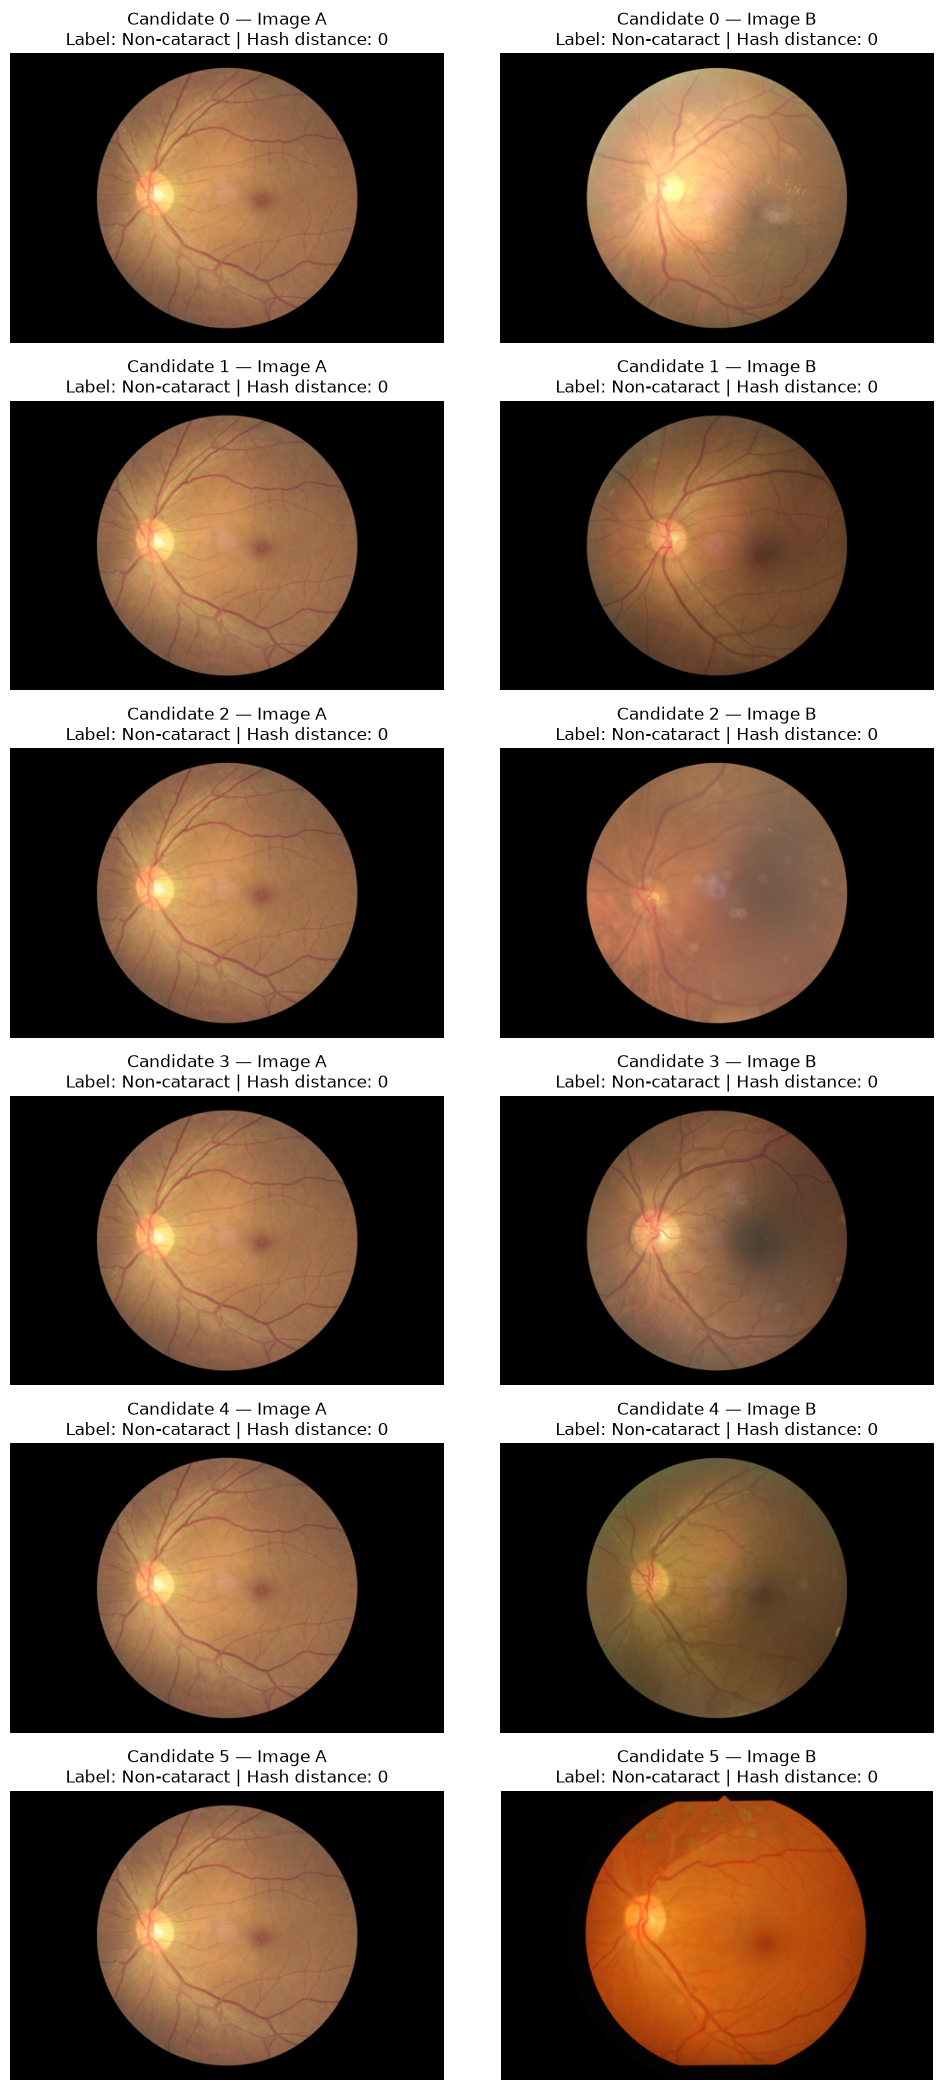

In [12]:
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

cross_patient_candidates = near_duplicate_candidates.loc[
    ~near_duplicate_candidates["same_patient"]
].copy()

preview_pairs = cross_patient_candidates.head(6)

if preview_pairs.empty:
    print(
        "No cross-patient candidate pairs found "
        "at the selected fingerprint threshold."
    )
else:
    fig, axes = plt.subplots(
        len(preview_pairs),
        2,
        figsize=(10, 3.5 * len(preview_pairs)),
        squeeze=False,
    )

    for plot_row, (pair_index, pair) in enumerate(
        preview_pairs.iterrows()
    ):
        for column, side in enumerate(["a", "b"]):
            image_path = PROJECT_ROOT / pair[f"image_path_{side}"]

            with Image.open(image_path) as original:
                image = ImageOps.exif_transpose(original).convert("RGB")
                image = ImageOps.contain(image, (500, 400))

            axes[plot_row, column].imshow(image)
            axes[plot_row, column].set_title(
                f"Candidate {pair_index} — Image {side.upper()}\n"
                f"Label: {CLASS_NAMES[int(pair[f'label_{side}'])]} | "
                f"Hash distance: {int(pair['dhash_distance'])}"
            )
            axes[plot_row, column].axis("off")

    plt.tight_layout()
    plt.show()

This coarse fingerprint screen produced many false candidate matches.
Its results were not used for image removal or patient grouping.
Do not rerun these screening cells during normal training.

## 8. Patient-Disjoint Dataset Splits

Create approximately 70% training, 15% validation and 15% test
partitions by patient, using seed 42.

Stratify patients by cataract presence and negative-cohort type.
Keep both eyes from each patient together.

Save and reuse patient assignments. Do not select a different
split based on model performance.

The coarse near-duplicate screening was unsuitable for these
images and is not used. Near-duplicates remain a limitation.

In [13]:
import gc
import hashlib
import json
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

# Release the large, rejected fingerprint-screening objects.
# This does not delete any files.
for variable_name in [
    "candidate_records",
    "near_duplicate_candidates",
    "cross_patient_candidates",
    "preview_pairs",
]:
    globals().pop(variable_name, None)

gc.collect()

SEED = 42
SPLIT_FRACTIONS = {
    "train": 0.70,
    "val": 0.15,
    "test": 0.15,
}

split_base = verified_manifest.copy()
split_base["patient_id"] = (
    split_base["patient_id"].astype("string")
)

if split_base["patient_id"].isna().any():
    raise ValueError("Missing patient IDs.")

if split_base["image_path"].duplicated().any():
    raise ValueError("Repeated image paths require investigation.")

if split_base["pixel_sha256"].duplicated().any():
    raise ValueError("Exact duplicate images require investigation.")

patient_groups = (
    split_base.groupby("patient_id", sort=True)
    .agg(
        has_cataract=("label", "max"),
        has_other_negative=(
            "evaluation_group",
            lambda values: values.eq("other_condition_negative").any(),
        ),
        eligible_images=("image_path", "size"),
    )
    .reset_index()
)

patient_groups["stratum"] = np.select(
    [
        patient_groups["has_cataract"].eq(1),
        patient_groups["has_other_negative"],
    ],
    ["cataract_present", "other_negative_without_cataract"],
    default="healthy_only",
)

# Fingerprint the cohort so saved splits cannot silently be
# reused with different images or labels.
fingerprint_columns = [
    "patient_id", "eye_side", "image_path",
    "label", "evaluation_group", "pixel_sha256",
]

cohort_text = (
    split_base[fingerprint_columns]
    .sort_values(["patient_id", "eye_side"])
    .to_csv(index=False, lineterminator="\n")
)

COHORT_SHA256 = hashlib.sha256(
    cohort_text.encode("utf-8")
).hexdigest()

print("PATIENT STRATA")
print(patient_groups["stratum"].value_counts().to_string())
print("\nEligible images:", len(split_base))
print("Eligible patients:", len(patient_groups))

PATIENT STRATA
stratum
other_negative_without_cataract    2069
healthy_only                       1080
cataract_present                    196

Eligible images: 6500
Eligible patients: 3345


In [14]:
SPLIT_DIR = PROJECT_ROOT / "data" / "splits"
SPLIT_DIR.mkdir(parents=True, exist_ok=True)

assignment_path = SPLIT_DIR / "patient_assignments.csv"
protocol_path = SPLIT_DIR / "split_protocol.json"

split_protocol = {
    "seed": SEED,
    "fractions": SPLIT_FRACTIONS,
    "cohort_sha256": COHORT_SHA256,
    "grouping": "patient_id",
    "stratification": "cataract presence, then negative-cohort type",
    "test_origin": "Internal holdout from annotated original training data",
    "near_duplicate_screening_used": False,
}

if assignment_path.exists() != protocol_path.exists():
    raise RuntimeError(
        "Only part of a saved split exists. "
        "Inspect the split folder before continuing."
    )

if assignment_path.exists():
    saved_protocol = json.loads(
        protocol_path.read_text(encoding="utf-8")
    )

    for key in ["seed", "fractions", "cohort_sha256"]:
        if saved_protocol.get(key) != split_protocol[key]:
            raise RuntimeError(
                f"Saved split differs in '{key}'. "
                "Do not overwrite it automatically."
            )

    patient_assignments = pd.read_csv(
        assignment_path,
        dtype={"patient_id": "string"},
    )

    print("Reloaded existing patient assignments.")

else:
    training_patients, holdout_patients = train_test_split(
        patient_groups,
        test_size=0.30,
        random_state=SEED,
        stratify=patient_groups["stratum"],
    )

    validation_patients, testing_patients = train_test_split(
        holdout_patients,
        test_size=0.50,
        random_state=SEED,
        stratify=holdout_patients["stratum"],
    )

    patient_assignments = pd.concat(
        [
            training_patients.assign(split="train"),
            validation_patients.assign(split="val"),
            testing_patients.assign(split="test"),
        ],
        ignore_index=True,
    )[["patient_id", "stratum", "split"]]

    print("Created patient assignments using seed 42.")

if patient_assignments["patient_id"].duplicated().any():
    raise ValueError("A patient has multiple assignments.")

if set(patient_assignments["patient_id"]) != set(
    patient_groups["patient_id"]
):
    raise ValueError("Saved assignments do not match the patient cohort.")

if set(patient_assignments["split"]) != {"train", "val", "test"}:
    raise ValueError("Unexpected split names.")

split_manifest = split_base.merge(
    patient_assignments[["patient_id", "split"]],
    on="patient_id",
    how="left",
    validate="many_to_one",
)

Created patient assignments using seed 42.


In [15]:
if split_manifest["split"].isna().any():
    raise ValueError("Some images have no split assignment.")

if len(split_manifest) != len(split_base):
    raise ValueError("Image count changed during splitting.")

# Explicit checks for overlap across partitions.
for column in ["patient_id", "image_path", "pixel_sha256"]:
    partitions_per_value = (
        split_manifest.groupby(column)["split"].nunique()
    )

    if partitions_per_value.gt(1).any():
        raise ValueError(f"Cross-partition overlap found: {column}")

split_summary = (
    split_manifest.groupby("split").agg(
        patients=("patient_id", "nunique"),
        images=("image_path", "size"),
        cataract_images=("label", "sum"),
    )
    .reindex(["train", "val", "test"])
)

split_summary["non_cataract_images"] = (
    split_summary["images"] - split_summary["cataract_images"]
)

if (
    split_summary[["cataract_images", "non_cataract_images"]] <= 0
).any().any():
    raise ValueError("Every partition must contain both binary classes.")

train_df = split_manifest.loc[
    split_manifest["split"].eq("train")
].reset_index(drop=True)

val_df = split_manifest.loc[
    split_manifest["split"].eq("val")
].reset_index(drop=True)

test_df = split_manifest.loc[
    split_manifest["split"].eq("test")
].reset_index(drop=True)

# Save assignments only when creating the split for the first time.
if not assignment_path.exists():
    patient_assignments.sort_values("patient_id").to_csv(
        assignment_path, index=False
    )
    protocol_path.write_text(
        json.dumps(split_protocol, indent=2),
        encoding="utf-8",
    )

for split_name, table in [
    ("train", train_df),
    ("val", val_df),
    ("test", test_df),
]:
    serialise_manifest(table).to_csv(
        SPLIT_DIR / f"{split_name}_manifest.csv",
        index=False,
    )

split_summary.to_csv(SPLIT_DIR / "split_summary.csv")

print("SPLIT SUMMARY")
print(split_summary.to_string())

print("\nIMAGE COUNTS BY EVALUATION GROUP")
print(
    pd.crosstab(
        split_manifest["split"],
        split_manifest["evaluation_group"],
    ).reindex(["train", "val", "test"]).to_string()
)

print("\nPatient, image-path and exact-pixel overlap checks passed.")
print("Saved splits:", SPLIT_DIR)

SPLIT SUMMARY
       patients  images  cataract_images  non_cataract_images
split                                                        
train      2341    4548              202                 4346
val         502     979               44                  935
test        502     973               41                  932

IMAGE COUNTS BY EVALUATION GROUP
evaluation_group  cataract  healthy_negative  other_condition_negative
split                                                                 
train                  202              1965                      2381
val                     44               422                       513
test                    41               431                       501

Patient, image-path and exact-pixel overlap checks passed.
Saved splits: C:\Users\Lenovo\OneDrive\Desktop\cataract-detection-odir\data\splits


## 9. Image Preprocessing and Data Loaders

Prepare RGB images at 224 × 224 pixels while preserving aspect ratio
through padding. Apply mild geometric augmentation during training.

Use deterministic preprocessing for validation. Apply ImageNet
normalisation consistently across models.

Keep the saved patient partitions unchanged.

In [3]:
from pathlib import Path
import json
import pandas as pd
import torch

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name != "cataract-detection-odir":
    raise RuntimeError(f"Unexpected project folder: {PROJECT_ROOT}")

AUDIT_DIR = PROJECT_ROOT / "results" / "data_audit"
SPLIT_DIR = PROJECT_ROOT / "data" / "splits"
AUDIT_DIR.mkdir(parents=True, exist_ok=True)

split_protocol = json.loads(
    (SPLIT_DIR / "split_protocol.json").read_text(encoding="utf-8")
)

SEED = split_protocol["seed"]
COHORT_SHA256 = split_protocol["cohort_sha256"]
CLASS_NAMES = ["Non-cataract", "Cataract"]
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

train_df = pd.read_csv(
    SPLIT_DIR / "train_manifest.csv",
    dtype={"patient_id": "string"},
)
val_df = pd.read_csv(
    SPLIT_DIR / "val_manifest.csv",
    dtype={"patient_id": "string"},
)

print("Paths and saved splits restored.")
print("Device:", DEVICE)
print("Training images:", len(train_df))
print("Validation images:", len(val_df))

Paths and saved splits restored.
Device: cuda
Training images: 4548
Validation images: 979


In [4]:
import json
import torch
from PIL import Image, ImageOps
from torchvision import transforms
from torchvision.transforms import InterpolationMode
from torch.utils.data import Dataset, DataLoader

IMAGE_SIZE = 224
BATCH_SIZE = 16
NUM_WORKERS = 0  # Start with this for Windows notebooks.

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

class ResizeWithPadding:
    def __init__(self, size):
        self.size = size

    def __call__(self, image):
        return ImageOps.pad(
            image,
            (self.size, self.size),
            method=Image.Resampling.BICUBIC,
            color=(0, 0, 0),
            centering=(0.5, 0.5),
        )

train_transform = transforms.Compose([
    ResizeWithPadding(IMAGE_SIZE),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(
        degrees=5,
        interpolation=InterpolationMode.BILINEAR,
        fill=0,
    ),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

eval_transform = transforms.Compose([
    ResizeWithPadding(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

preprocessing_protocol = {
    "image_size": IMAGE_SIZE,
    "resize": "Aspect-preserving padding",
    "resize_interpolation": "Bicubic",
    "padding_color": [0, 0, 0],
    "training_horizontal_flip_probability": 0.5,
    "training_rotation_degrees": 5,
    "normalisation_mean": IMAGENET_MEAN,
    "normalisation_std": IMAGENET_STD,
    "batch_size": BATCH_SIZE,
    "num_workers": NUM_WORKERS,
}

(AUDIT_DIR / "preprocessing_protocol.json").write_text(
    json.dumps(preprocessing_protocol, indent=2),
    encoding="utf-8",
)

print("Preprocessing configured.")
print("Image size:", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)

Preprocessing configured.
Image size: 224
Batch size: 16


In [5]:
class CataractDataset(Dataset):
    def __init__(self, manifest, project_root, transform):
        self.manifest = manifest.reset_index(drop=True).copy()
        self.project_root = project_root
        self.transform = transform

    def __len__(self):
        return len(self.manifest)

    def __getitem__(self, index):
        row = self.manifest.iloc[index]
        image_path = self.project_root / row["image_path"]

        with Image.open(image_path) as original:
            image = ImageOps.exif_transpose(original).convert("RGB")
            image = self.transform(image)

        return {
            "image": image,
            # Float labels are suitable for binary logit loss.
            "label": torch.tensor(
                float(row["label"]), dtype=torch.float32
            ),
            "row_index": index,
        }


def make_data_loaders(training_manifest, seed=SEED):
    training_dataset = CataractDataset(
        training_manifest, PROJECT_ROOT, train_transform
    )
    validation_dataset = CataractDataset(
        val_df, PROJECT_ROOT, eval_transform
    )

    generator = torch.Generator().manual_seed(seed)

    training_loader = DataLoader(
        training_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generator,
        num_workers=NUM_WORKERS,
        pin_memory=(DEVICE.type == "cuda"),
        drop_last=False,
    )

    validation_loader = DataLoader(
        validation_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=(DEVICE.type == "cuda"),
        drop_last=False,
    )

    return training_loader, validation_loader


train_loader, val_loader = make_data_loaders(train_df)

print("Training images:", len(train_loader.dataset))
print("Validation images:", len(val_loader.dataset))
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training images: 4548
Validation images: 979
Training batches: 285
Validation batches: 62


BATCH CHECK
Image shape: (16, 3, 224, 224)
Label shape: (16,)
Image dtype: torch.float32
Label dtype: torch.float32
Finite image values: True
Labels present: [0.0, 1.0]


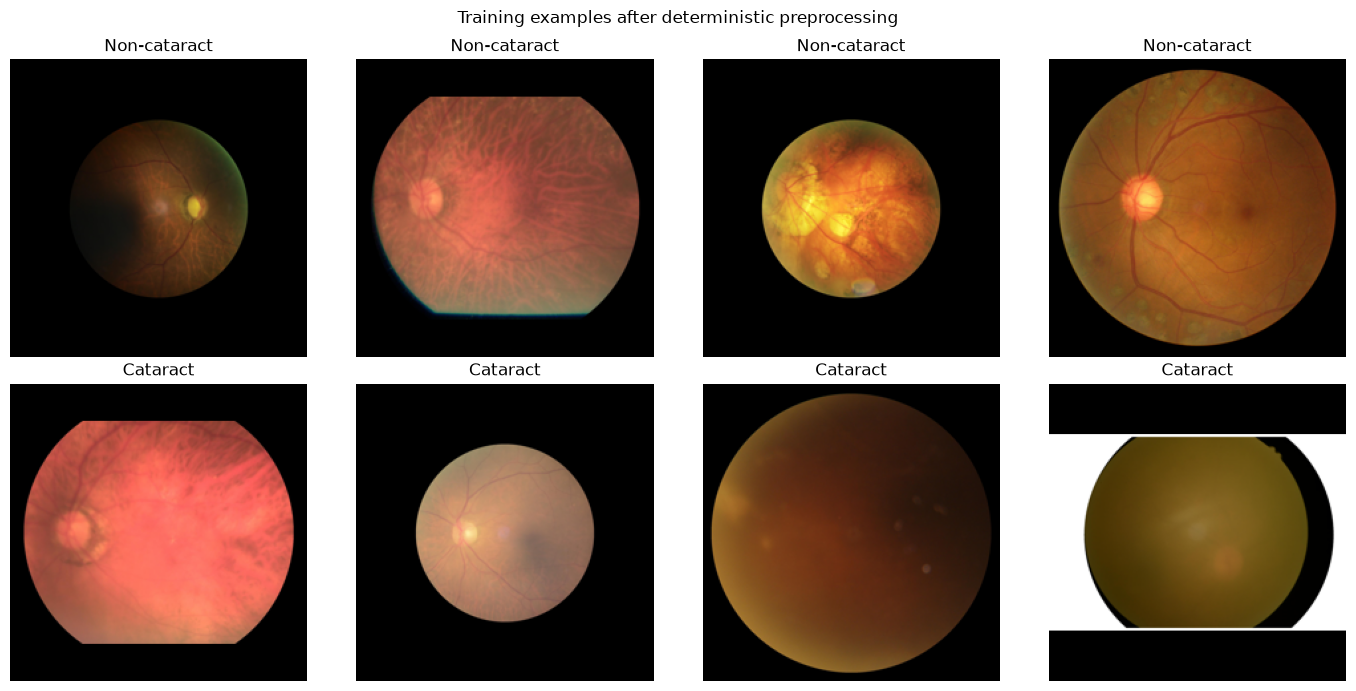


Data loaders ready. No model has been trained yet.


In [18]:
import matplotlib.pyplot as plt

batch = next(iter(train_loader))

print("BATCH CHECK")
print("Image shape:", tuple(batch["image"].shape))
print("Label shape:", tuple(batch["label"].shape))
print("Image dtype:", batch["image"].dtype)
print("Label dtype:", batch["label"].dtype)
print("Finite image values:", bool(torch.isfinite(batch["image"]).all()))
print("Labels present:", torch.unique(batch["label"]).tolist())

assert batch["image"].shape[1:] == (3, IMAGE_SIZE, IMAGE_SIZE)
assert torch.isfinite(batch["image"]).all()
assert set(batch["label"].tolist()).issubset({0.0, 1.0})

# Show up to four training examples from each binary class,
# using deterministic preprocessing for an easier visual check.
preview_df = pd.concat([
    train_df.loc[train_df["label"].eq(label)].sample(
        n=min(4, int(train_df["label"].eq(label).sum())),
        random_state=SEED,
    )
    for label in [0, 1]
], ignore_index=True)

preview_dataset = CataractDataset(
    preview_df, PROJECT_ROOT, eval_transform
)

mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
std = torch.tensor(IMAGENET_STD).view(3, 1, 1)

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
axes = axes.ravel()

for axis in axes:
    axis.axis("off")

for index in range(len(preview_dataset)):
    sample = preview_dataset[index]
    image = (sample["image"] * std + mean).clamp(0, 1)

    axes[index].imshow(image.permute(1, 2, 0).numpy())
    axes[index].set_title(
        CLASS_NAMES[int(sample["label"].item())]
    )

plt.suptitle("Training examples after deterministic preprocessing")
plt.tight_layout()
plt.show()

# Reset the loader's shuffle generator after this inspection.
train_loader, val_loader = make_data_loaders(train_df)

print("\nData loaders ready. No model has been trained yet.")

## 10. Custom CNN and Training Configuration

Build a small CNN trained from scratch as the baseline.

Use one output logit with weighted BCEWithLogitsLoss.
Compute the positive-class weight from training labels only.

Select checkpoints using validation average precision.
Use validation performance for scheduling and early stopping.

In [6]:
import random
import numpy as np
import torch
from torch import nn

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True


seed_everything(SEED)

MAX_EPOCHS = 25
EARLY_STOPPING_PATIENCE = 5
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
DROPOUT = 0.3

positive_count = int(train_df["label"].eq(1).sum())
negative_count = int(train_df["label"].eq(0).sum())

if positive_count == 0 or negative_count == 0:
    raise ValueError("Training data must contain both classes.")

POSITIVE_WEIGHT = negative_count / positive_count

train_criterion = nn.BCEWithLogitsLoss(
    pos_weight=torch.tensor(
        [POSITIVE_WEIGHT],
        dtype=torch.float32,
        device=DEVICE,
    )
)

# Unweighted validation loss for reporting.
eval_criterion = nn.BCEWithLogitsLoss()

print("Training positives:", positive_count)
print("Training negatives:", negative_count)
print(f"Positive loss weight: {POSITIVE_WEIGHT:.4f}")
print("Checkpoint selection: validation average precision")

Training positives: 202
Training negatives: 4346
Positive loss weight: 21.5149
Checkpoint selection: validation average precision


In [7]:
class CustomCataractCNN(nn.Module):
    def __init__(self, dropout=0.3):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )

        self.pool = nn.AdaptiveAvgPool2d((4, 4))

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 128),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(128, 1),
        )

    def forward(self, images):
        features = self.features(images)
        pooled = self.pool(features)
        return self.classifier(pooled).squeeze(1)


baseline_model = CustomCataractCNN(
    dropout=DROPOUT
).to(DEVICE)

optimizer = torch.optim.AdamW(
    baseline_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
)

AMP_ENABLED = DEVICE.type == "cuda"
scaler = torch.amp.GradScaler(
    "cuda", enabled=AMP_ENABLED
)

parameter_count = sum(
    parameter.numel()
    for parameter in baseline_model.parameters()
)

print("Model: CustomCataractCNN")
print(f"Parameters: {parameter_count:,}")
print("Device:", DEVICE)
print("Mixed precision enabled:", AMP_ENABLED)

Model: CustomCataractCNN
Parameters: 355,873
Device: cuda
Mixed precision enabled: True


In [7]:
import json
from datetime import datetime, timezone

BASELINE_RUN_NAME = (
    f"custom_cnn_seed{SEED}_"
    + datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
)

BASELINE_MODEL_DIR = PROJECT_ROOT / "models" / BASELINE_RUN_NAME
BASELINE_RESULT_DIR = PROJECT_ROOT / "results" / BASELINE_RUN_NAME

BASELINE_MODEL_DIR.mkdir(parents=True, exist_ok=True)
BASELINE_RESULT_DIR.mkdir(parents=True, exist_ok=True)

baseline_config = {
    "run_name": BASELINE_RUN_NAME,
    "architecture": "CustomCataractCNN",
    "seed": SEED,
    "class_names": CLASS_NAMES,
    "parameter_count": parameter_count,
    "cohort_sha256": COHORT_SHA256,
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "dropout": DROPOUT,
    "optimizer": "AdamW",
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "positive_loss_weight": POSITIVE_WEIGHT,
    "max_epochs": MAX_EPOCHS,
    "early_stopping_patience": EARLY_STOPPING_PATIENCE,
    "selection_metric": "validation_average_precision",
    "scheduler": {
        "name": "ReduceLROnPlateau",
        "mode": "max",
        "factor": 0.5,
        "patience": 2,
        "min_lr": 1e-6,
    },
    "mixed_precision": AMP_ENABLED,
    "preprocessing": preprocessing_protocol,
}

(BASELINE_RESULT_DIR / "config.json").write_text(
    json.dumps(baseline_config, indent=2),
    encoding="utf-8",
)

# Use validation data for a forward-pass check without changing
# model weights or batch-normalisation running statistics.
check_batch = next(iter(val_loader))
check_images = check_batch["image"].to(DEVICE)
check_labels = check_batch["label"].to(DEVICE)

baseline_model.eval()

with torch.inference_mode():
    check_logits = baseline_model(check_images)
    check_loss = eval_criterion(check_logits, check_labels)

assert check_logits.shape == check_labels.shape
assert torch.isfinite(check_logits).all()
assert torch.isfinite(check_loss)

print("FORWARD-PASS CHECK PASSED")
print("Output shape:", tuple(check_logits.shape))
print(f"Initial untrained validation-batch loss: {check_loss.item():.4f}")
print("\nCheckpoint folder:", BASELINE_MODEL_DIR)
print("Results folder:", BASELINE_RESULT_DIR)

del check_images, check_labels, check_logits, check_batch

# Fresh loaders for the training run.
train_loader, val_loader = make_data_loaders(train_df)

FORWARD-PASS CHECK PASSED
Output shape: (16,)
Initial untrained validation-batch loss: 0.7480

Checkpoint folder: C:\Users\Lenovo\OneDrive\Desktop\cataract-detection-odir\models\custom_cnn_seed42_20261031T021459_849813Z
Results folder: C:\Users\Lenovo\OneDrive\Desktop\cataract-detection-odir\results\custom_cnn_seed42_20261031T021459_849813Z


## 11. Baseline CNN Training

Train the custom CNN using weighted binary cross-entropy and AdamW.

Select the checkpoint with the highest validation average precision.
Reduce the learning rate on a validation plateau and stop after
five epochs without improvement.

Save training history and the best validation predictions.
The test set is not evaluated during training.

In [8]:
import time
import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    confusion_matrix,
    f1_score,
)


def run_binary_epoch(
    model,
    loader,
    criterion,
    optimizer=None,
    scaler=None,
):
    training = optimizer is not None
    model.train(training)

    total_loss = 0.0
    total_images = 0
    collected_labels = []
    collected_scores = []
    collected_indices = []

    phase = "Training" if training else "Validation"

    for batch_number, batch in enumerate(loader, start=1):
        images = batch["image"].to(DEVICE, non_blocking=True)
        labels = batch["label"].to(DEVICE, non_blocking=True)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            # Validate in float32 for consistent saved predictions.
            with torch.autocast(
                device_type=DEVICE.type,
                enabled=AMP_ENABLED and training,
            ):
                logits = model(images)

                if logits.shape != labels.shape:
                    raise ValueError(
                        f"Output shape {logits.shape} "
                        f"does not match labels {labels.shape}"
                    )

                loss = criterion(logits, labels)

            if not torch.isfinite(loss).item():
                raise FloatingPointError(
                    f"Non-finite loss during {phase.lower()}."
                )

            if training:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()

        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size
        total_images += batch_size

        scores = torch.sigmoid(logits.detach().float())

        collected_labels.extend(
            labels.detach().cpu().numpy().astype(int).tolist()
        )
        collected_scores.extend(scores.cpu().tolist())
        collected_indices.extend(batch["row_index"].tolist())

        progress_interval = 100 if training else 30

        if (
            batch_number % progress_interval == 0
            or batch_number == len(loader)
        ):
            print(
                f"  {phase}: batch {batch_number}/{len(loader)}",
                flush=True,
            )

    y_true = np.asarray(collected_labels)
    y_score = np.asarray(collected_scores)
    y_pred = (y_score >= 0.5).astype(int)

    if not np.isfinite(y_score).all():
        raise FloatingPointError("Non-finite prediction scores.")

    if len(np.unique(y_true)) != 2:
        raise ValueError("Both classes are required for these metrics.")

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    sensitivity = tp / (tp + fn)
    specificity = tn / (tn + fp)

    metrics = {
        "loss": float(total_loss / total_images),
        "average_precision": float(
            average_precision_score(y_true, y_score)
        ),
        "auroc": float(roc_auc_score(y_true, y_score)),
        "accuracy": float((y_true == y_pred).mean()),
        "balanced_accuracy": float(
            (sensitivity + specificity) / 2
        ),
        "sensitivity": float(sensitivity),
        "specificity": float(specificity),
        "f1": float(f1_score(y_true, y_pred, zero_division=0)),
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp),
    }

    predictions = pd.DataFrame({
        "row_index": collected_indices,
        "true_label": y_true,
        "cataract_score": y_score,
        "predicted_label": y_pred,
    })

    if not training:
        expected_indices = set(range(len(loader.dataset)))

        if (
            predictions["row_index"].duplicated().any()
            or set(predictions["row_index"]) != expected_indices
        ):
            raise ValueError(
                "Validation predictions do not cover each image once."
            )

    return metrics, predictions


print("Training and evaluation helper ready.")

Training and evaluation helper ready.


In [10]:
import json
import time
from datetime import datetime, timezone
import pandas as pd
import torch
# Always continue the original saved run.
BASELINE_RUN_NAME = "custom_cnn_seed42_20261030T172651_792236Z"

BASELINE_MODEL_DIR = (
    PROJECT_ROOT / "models" / BASELINE_RUN_NAME
)
BASELINE_RESULT_DIR = (
    PROJECT_ROOT / "results" / BASELINE_RUN_NAME
)

PAUSE_PATH = BASELINE_MODEL_DIR / "paused_training.pth"
BEST_BASELINE_PATH = BASELINE_MODEL_DIR / "best.pth"
HISTORY_PATH = BASELINE_RESULT_DIR / "training_history.csv"

if not PAUSE_PATH.is_file():
    raise FileNotFoundError(f"Missing checkpoint: {PAUSE_PATH}")

print("Continuing saved run:", BASELINE_RUN_NAME)
LATEST_BASELINE_PATH = BASELINE_MODEL_DIR / "latest_training.pth"

# Prefer a newer continuation checkpoint when one exists.
resume_path = (
    LATEST_BASELINE_PATH
    if LATEST_BASELINE_PATH.is_file()
    else PAUSE_PATH
)

state = torch.load(
    resume_path, map_location="cpu", weights_only=True
)

if state["config"]["cohort_sha256"] != COHORT_SHA256:
    raise ValueError("Checkpoint cohort does not match the saved splits.")

if state["config"]["run_name"] != BASELINE_RUN_NAME:
    raise ValueError("Checkpoint belongs to a different run.")

# Restore learned parameters and training state.
baseline_model.load_state_dict(state["model_state_dict"])
optimizer.load_state_dict(state["optimizer_state_dict"])
scheduler.load_state_dict(state["scheduler_state_dict"])
scaler.load_state_dict(state["scaler_state_dict"])
optimizer.zero_grad(set_to_none=True)

baseline_config = state["config"]
baseline_history = list(state["history"])
best_average_precision = float(state["best_average_precision"])
best_epoch = state["best_epoch"]
epochs_without_improvement = int(
    state["epochs_without_improvement"]
)

MAX_EPOCHS = baseline_config["max_epochs"]
EARLY_STOPPING_PATIENCE = baseline_config["early_stopping_patience"]

START_EPOCH = max(
    (int(record["epoch"]) for record in baseline_history),
    default=0,
) + 1

train_loader, val_loader = make_data_loaders(train_df)

# New checkpoints retain these states for future continuation.
if "torch_rng_state" in state:
    torch.set_rng_state(state["torch_rng_state"])

if DEVICE.type == "cuda" and state.get("cuda_rng_states"):
    torch.cuda.set_rng_state_all(state["cuda_rng_states"])

if "loader_generator_state" in state:
    train_loader.generator.set_state(
        state["loader_generator_state"]
    )

resume_note = {
    "time_utc": datetime.now(timezone.utc).isoformat(),
    "source_checkpoint": resume_path.name,
    "next_epoch": START_EPOCH,
    "partial_epoch_repeated": (
        state.get("checkpoint_kind", "partial_epoch") == "partial_epoch"
    ),
}

resume_log_path = BASELINE_RESULT_DIR / "resume_log.json"
resume_log = (
    json.loads(resume_log_path.read_text(encoding="utf-8"))
    if resume_log_path.is_file()
    else []
)
resume_log.append(resume_note)
resume_log_path.write_text(
    json.dumps(resume_log, indent=2), encoding="utf-8"
)


def atomic_torch_save(payload, destination):
    temporary = destination.with_suffix(".tmp")
    torch.save(payload, temporary)
    temporary.replace(destination)


def save_latest_training(checkpoint_kind, complete=False):
    atomic_torch_save(
        {
            "model_state_dict": {
                name: value.detach().cpu().clone()
                for name, value in baseline_model.state_dict().items()
            },
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "scaler_state_dict": scaler.state_dict(),
            "config": baseline_config,
            "epoch_at_interruption": epoch,
            "history": baseline_history,
            "best_average_precision": best_average_precision,
            "best_epoch": best_epoch,
            "epochs_without_improvement": epochs_without_improvement,
            "run_name": BASELINE_RUN_NAME,
            "model_directory": str(BASELINE_MODEL_DIR),
            "result_directory": str(BASELINE_RESULT_DIR),
            "checkpoint_kind": checkpoint_kind,
            "training_complete": complete,
            "torch_rng_state": torch.get_rng_state(),
            "cuda_rng_states": (
                torch.cuda.get_rng_state_all()
                if DEVICE.type == "cuda"
                else []
            ),
            "loader_generator_state": (
                train_loader.generator.get_state()
            ),
        },
        LATEST_BASELINE_PATH,
    )

    temporary_history = HISTORY_PATH.with_suffix(".tmp")
    pd.DataFrame(baseline_history).to_csv(
        temporary_history, index=False
    )
    temporary_history.replace(HISTORY_PATH)


epoch = START_EPOCH - 1
interrupted = False

print("Restored:", resume_path.name)
print("Next epoch:", START_EPOCH)
print("Best epoch so far:", best_epoch)
print(f"Best validation AP: {best_average_precision:.4f}")

already_finished = (
    state.get("training_complete", False)
    or START_EPOCH > MAX_EPOCHS
    or epochs_without_improvement >= EARLY_STOPPING_PATIENCE
)

try:
    if already_finished:
        print("Training has already met its stopping condition.")
    else:
        for epoch in range(START_EPOCH, MAX_EPOCHS + 1):
            epoch_start = time.perf_counter()
            learning_rate_used = optimizer.param_groups[0]["lr"]

            print(f"\nEpoch {epoch}/{MAX_EPOCHS}", flush=True)

            train_metrics, _ = run_binary_epoch(
                baseline_model,
                train_loader,
                train_criterion,
                optimizer=optimizer,
                scaler=scaler,
            )

            val_metrics, val_predictions = run_binary_epoch(
                baseline_model, val_loader, eval_criterion
            )

            validation_ap = val_metrics["average_precision"]
            improved = validation_ap > best_average_precision

            if improved:
                metadata = val_loader.dataset.manifest[
                    ["patient_id", "image_path", "evaluation_group", "label"]
                ].copy()
                metadata.index.name = "row_index"

                saved_predictions = val_predictions.merge(
                    metadata.reset_index(),
                    on="row_index",
                    how="left",
                    validate="one_to_one",
                )

                if not saved_predictions["true_label"].eq(
                    saved_predictions["label"]
                ).all():
                    raise ValueError("Validation label alignment failed.")

                atomic_torch_save(
                    {
                        "model_state_dict": {
                            name: value.detach().cpu().clone()
                            for name, value
                            in baseline_model.state_dict().items()
                        },
                        "epoch": epoch,
                        "validation_metrics": val_metrics,
                        "config": baseline_config,
                    },
                    BEST_BASELINE_PATH,
                )

                saved_predictions.sort_values("row_index").to_csv(
                    BASELINE_RESULT_DIR / "validation_predictions.csv",
                    index=False,
                )

                best_average_precision = validation_ap
                best_epoch = epoch
                epochs_without_improvement = 0
            else:
                epochs_without_improvement += 1

            scheduler.step(validation_ap)
            epoch_seconds = time.perf_counter() - epoch_start

            baseline_history.append({
                "epoch": epoch,
                "learning_rate": learning_rate_used,
                "epoch_seconds": epoch_seconds,
                "checkpoint_improved": improved,
                **{
                    f"train_{key}": value
                    for key, value in train_metrics.items()
                },
                **{
                    f"val_{key}": value
                    for key, value in val_metrics.items()
                },
            })

            save_latest_training("epoch_boundary")

            print(
                f"Train weighted loss: {train_metrics['loss']:.4f} | "
                f"Val unweighted loss: {val_metrics['loss']:.4f}\n"
                f"Val AP: {validation_ap:.4f} | "
                f"AUROC: {val_metrics['auroc']:.4f} | "
                f"Sensitivity: {val_metrics['sensitivity']:.3f} | "
                f"Specificity: {val_metrics['specificity']:.3f}\n"
                f"Epoch time: {epoch_seconds:.1f}s | "
                f"Best checkpoint: {'saved' if improved else 'unchanged'}",
                flush=True,
            )

            if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
                print("\nEarly stopping triggered.")
                break

except KeyboardInterrupt:
    interrupted = True
    save_latest_training("partial_epoch")
    print("\nInterrupted. Current training state saved:")
    print(LATEST_BASELINE_PATH)

baseline_training_history = pd.DataFrame(baseline_history)

if not interrupted:
    save_latest_training("epoch_boundary", complete=True)

    training_summary = {
        "run_name": BASELINE_RUN_NAME,
        "epochs_completed": len(baseline_history),
        "best_epoch": best_epoch,
        "best_validation_average_precision": best_average_precision,
        "checkpoint": BEST_BASELINE_PATH.relative_to(
            PROJECT_ROOT
        ).as_posix(),
        "training_complete": True,
    }

    (BASELINE_RESULT_DIR / "training_summary.json").write_text(
        json.dumps(training_summary, indent=2),
        encoding="utf-8",
    )

    print("\nTRAINING COMPLETE")
    print(json.dumps(training_summary, indent=2))

Continuing saved run: custom_cnn_seed42_20261030T172651_792236Z
Restored: latest_training.pth
Next epoch: 26
Best epoch so far: 25
Best validation AP: 0.6493
Training has already met its stopping condition.

TRAINING COMPLETE
{
  "run_name": "custom_cnn_seed42_20261030T172651_792236Z",
  "epochs_completed": 25,
  "best_epoch": 25,
  "best_validation_average_precision": 0.649256855604547,
  "checkpoint": "models/custom_cnn_seed42_20261030T172651_792236Z/best.pth",
  "training_complete": true
}


BEST BASELINE — VALIDATION
Selected epoch: 25
Decision threshold: 0.5

   average_precision: 0.6493
               auroc: 0.9555
            accuracy: 0.9234
   balanced_accuracy: 0.9057
           precision: 0.3578
         sensitivity: 0.8864
         specificity: 0.9251
                  f1: 0.5098
                loss: 0.1941

Confusion-matrix counts:
TN: 865
FP: 70
FN: 5
TP: 39


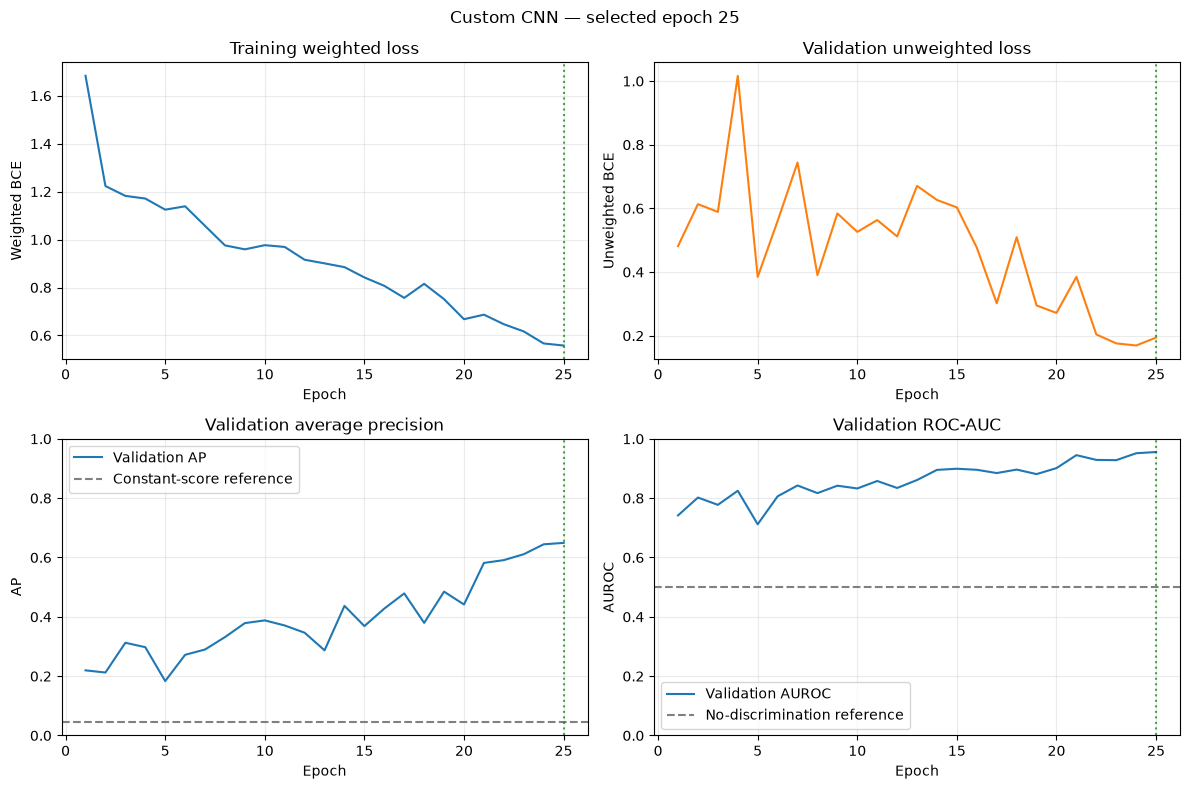


Metrics and curves saved: C:\Users\Lenovo\OneDrive\Desktop\cataract-detection-odir\results\custom_cnn_seed42_20261030T172651_792236Z
Best checkpoint loaded. Test set remains unevaluated.


In [11]:
import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

# Load the selected checkpoint.
baseline_checkpoint = torch.load(
    BEST_BASELINE_PATH,
    map_location="cpu",
    weights_only=True,
)

baseline_model.load_state_dict(
    baseline_checkpoint["model_state_dict"]
)
baseline_model.to(DEVICE)
baseline_model.eval()

baseline_best_epoch = int(baseline_checkpoint["epoch"])
baseline_best_validation_metrics = dict(
    baseline_checkpoint["validation_metrics"]
)

# Add precision from the saved confusion-matrix counts.
tp = baseline_best_validation_metrics["tp"]
fp = baseline_best_validation_metrics["fp"]

baseline_best_validation_metrics["precision"] = (
    tp / (tp + fp) if tp + fp > 0 else 0.0
)

history = (
    pd.read_csv(HISTORY_PATH)
    .sort_values("epoch")
    .reset_index(drop=True)
)

if history["epoch"].duplicated().any():
    raise ValueError("Repeated epoch records found in training history.")

selected_record = history.loc[
    history["epoch"].eq(baseline_best_epoch)
]

if len(selected_record) != 1:
    raise ValueError("Best checkpoint epoch is missing from history.")

if not np.isclose(
    selected_record.iloc[0]["val_average_precision"],
    baseline_best_validation_metrics["average_precision"],
    atol=1e-6,
    rtol=0,
):
    raise ValueError("Checkpoint AP does not match training history.")

# Save a compact metrics table for later model comparisons.
baseline_metrics_table = pd.DataFrame([{
    "model": "Custom CNN",
    "selected_epoch": baseline_best_epoch,
    "threshold": 0.5,
    **baseline_best_validation_metrics,
}])

baseline_metrics_table.to_csv(
    BASELINE_RESULT_DIR / "validation_metrics.csv",
    index=False,
)

print("BEST BASELINE — VALIDATION")
print("Selected epoch:", baseline_best_epoch)
print("Decision threshold: 0.5\n")

metric_order = [
    "average_precision",
    "auroc",
    "accuracy",
    "balanced_accuracy",
    "precision",
    "sensitivity",
    "specificity",
    "f1",
    "loss",
]

for metric in metric_order:
    print(
        f"{metric:>20}: "
        f"{baseline_best_validation_metrics[metric]:.4f}"
    )

print("\nConfusion-matrix counts:")
for metric in ["tn", "fp", "fn", "tp"]:
    print(
        f"{metric.upper()}: "
        f"{int(baseline_best_validation_metrics[metric])}"
    )

# Learning curves: keep the differently weighted losses separate.
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0, 0].plot(
    history["epoch"], history["train_loss"], color="tab:blue"
)
axes[0, 0].set_title("Training weighted loss")
axes[0, 0].set_ylabel("Weighted BCE")

axes[0, 1].plot(
    history["epoch"], history["val_loss"], color="tab:orange"
)
axes[0, 1].set_title("Validation unweighted loss")
axes[0, 1].set_ylabel("Unweighted BCE")

axes[1, 0].plot(
    history["epoch"],
    history["val_average_precision"],
    label="Validation AP",
)
axes[1, 0].axhline(
    float(val_df["label"].mean()),
    color="gray",
    linestyle="--",
    label="Constant-score reference",
)
axes[1, 0].set_title("Validation average precision")
axes[1, 0].set_ylabel("AP")
axes[1, 0].set_ylim(0, 1)
axes[1, 0].legend()

axes[1, 1].plot(
    history["epoch"], history["val_auroc"], label="Validation AUROC"
)
axes[1, 1].axhline(
    0.5,
    color="gray",
    linestyle="--",
    label="No-discrimination reference",
)
axes[1, 1].set_title("Validation ROC-AUC")
axes[1, 1].set_ylabel("AUROC")
axes[1, 1].set_ylim(0, 1)
axes[1, 1].legend()

for axis in axes.ravel():
    axis.axvline(
        baseline_best_epoch,
        color="green",
        linestyle=":",
        alpha=0.7,
    )
    axis.set_xlabel("Epoch")
    axis.grid(alpha=0.25)

fig.suptitle(
    f"Custom CNN — selected epoch {baseline_best_epoch}"
)
fig.tight_layout()

fig.savefig(
    BASELINE_RESULT_DIR / "training_curves.png",
    dpi=180,
    bbox_inches="tight",
)
plt.show()

print("\nMetrics and curves saved:", BASELINE_RESULT_DIR)
print("Best checkpoint loaded. Test set remains unevaluated.")

## 12. Baseline Validation Analysis

Evaluate the selected custom CNN at the fixed threshold of 0.5.

Plot ROC and precision–recall curves, a confusion matrix and score
distributions. Compare against an always-non-cataract reference.

Examine false-positive rates separately for healthy negatives and
other-condition negatives. The test set remains unevaluated.

In [12]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_score,
    roc_auc_score,
)

BASELINE_EVAL_DIR = BASELINE_RESULT_DIR / "validation_analysis"
BASELINE_EVAL_DIR.mkdir(parents=True, exist_ok=True)

saved_predictions = pd.read_csv(
    BASELINE_RESULT_DIR / "validation_predictions.csv",
    dtype={"patient_id": "string"},
).sort_values("row_index").reset_index(drop=True)

expected = val_df.reset_index(drop=True).copy()

# Verify that scores correspond to the saved validation images.
if not np.array_equal(
    saved_predictions["row_index"].to_numpy(),
    np.arange(len(expected)),
):
    raise ValueError("Validation row indices do not match.")

if not np.array_equal(
    saved_predictions["true_label"].to_numpy(),
    expected["label"].to_numpy(),
):
    raise ValueError("Validation labels do not match.")

for column in ["patient_id", "image_path", "evaluation_group"]:
    if not np.array_equal(
        saved_predictions[column].astype("string").to_numpy(),
        expected[column].astype("string").to_numpy(),
    ):
        raise ValueError(f"Validation metadata mismatch: {column}")

baseline_val = expected.copy()
baseline_val["row_index"] = np.arange(len(expected))
baseline_val["cataract_score"] = (
    saved_predictions["cataract_score"].to_numpy(dtype=float)
)

scores = baseline_val["cataract_score"].to_numpy()
y_true = baseline_val["label"].to_numpy(dtype=int)

if not np.isfinite(scores).all() or not (
    (scores >= 0) & (scores <= 1)
).all():
    raise ValueError("Invalid prediction scores.")

BASELINE_THRESHOLD = 0.5
baseline_val["predicted_label"] = (
    scores >= BASELINE_THRESHOLD
).astype(int)


def detection_metrics(labels, prediction_scores, threshold=0.5):
    predictions = (prediction_scores >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(
        labels, predictions, labels=[0, 1]
    ).ravel()

    sensitivity = tp / (tp + fn)
    specificity = tn / (tn + fp)

    return {
        "accuracy": accuracy_score(labels, predictions),
        "balanced_accuracy": (sensitivity + specificity) / 2,
        "precision": precision_score(
            labels, predictions, zero_division=0
        ),
        "sensitivity": sensitivity,
        "specificity": specificity,
        "f1": f1_score(labels, predictions, zero_division=0),
        "auroc": roc_auc_score(labels, prediction_scores),
        "average_precision": average_precision_score(
            labels, prediction_scores
        ),
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp),
    }


baseline_validation_metrics = detection_metrics(y_true, scores)

# Check consistency with the checkpoint metrics saved in Section 11.
recorded_metrics = pd.read_csv(
    BASELINE_RESULT_DIR / "validation_metrics.csv"
).iloc[0]

for metric in ["average_precision", "auroc"]:
    if not np.isclose(
        baseline_validation_metrics[metric],
        float(recorded_metrics[metric]),
        atol=1e-6,
        rtol=0,
    ):
        raise ValueError(f"Saved predictions disagree on {metric}.")

reference_metrics = detection_metrics(
    y_true, np.zeros(len(y_true), dtype=float)
)

baseline_validation_comparison = pd.DataFrame([
    {"model": "Custom CNN", **baseline_validation_metrics},
    {"model": "Always non-cataract", **reference_metrics},
])

baseline_validation_comparison.to_csv(
    BASELINE_EVAL_DIR / "metrics_comparison.csv",
    index=False,
)

print("VALIDATION — FIXED THRESHOLD 0.5")
print(baseline_validation_comparison.round(4).to_string(index=False))
print("\nPrediction and metadata checks passed.")


VALIDATION — FIXED THRESHOLD 0.5
              model  accuracy  balanced_accuracy  precision  sensitivity  specificity     f1  auroc  average_precision  tn  fp  fn  tp
         Custom CNN    0.9234             0.9057     0.3578       0.8864       0.9251 0.5098 0.9555             0.6493 865  70   5  39
Always non-cataract    0.9551             0.5000     0.0000       0.0000       1.0000 0.0000 0.5000             0.0449 935   0  44   0

Prediction and metadata checks passed.


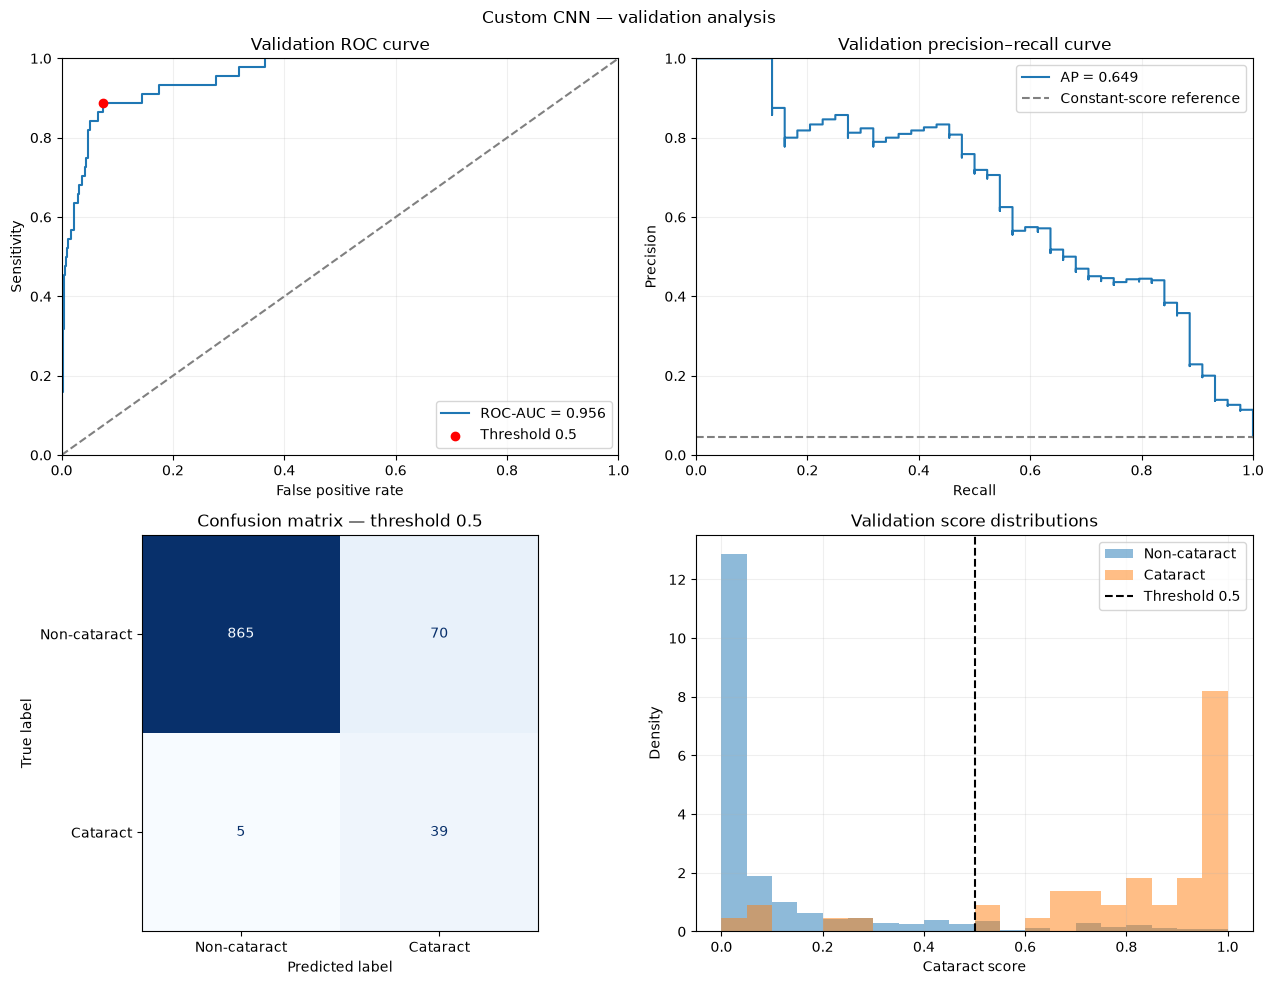

In [13]:
import matplotlib.pyplot as plt

from sklearn.metrics import (
    ConfusionMatrixDisplay,
    precision_recall_curve,
    roc_curve,
)

fpr, tpr, roc_thresholds = roc_curve(y_true, scores)
precision_values, recall_values, pr_thresholds = (
    precision_recall_curve(y_true, scores)
)

pd.DataFrame({
    "false_positive_rate": fpr,
    "true_positive_rate": tpr,
    "threshold": roc_thresholds,
}).to_csv(BASELINE_EVAL_DIR / "roc_points.csv", index=False)

pd.DataFrame({
    "recall": recall_values,
    "precision": precision_values,
    "threshold": np.append(pr_thresholds, np.nan),
}).to_csv(BASELINE_EVAL_DIR / "pr_points.csv", index=False)

cm = confusion_matrix(
    y_true,
    baseline_val["predicted_label"],
    labels=[0, 1],
)

pd.DataFrame(
    cm,
    index=["True non-cataract", "True cataract"],
    columns=["Predicted non-cataract", "Predicted cataract"],
).to_csv(BASELINE_EVAL_DIR / "confusion_matrix.csv")

fig, axes = plt.subplots(2, 2, figsize=(13, 10))

axes[0, 0].plot(
    fpr, tpr,
    label=f"ROC-AUC = {baseline_validation_metrics['auroc']:.3f}",
)
axes[0, 0].plot([0, 1], [0, 1], "--", color="gray")
axes[0, 0].scatter(
    1 - baseline_validation_metrics["specificity"],
    baseline_validation_metrics["sensitivity"],
    color="red",
    label="Threshold 0.5",
    zorder=3,
)
axes[0, 0].set(
    title="Validation ROC curve",
    xlabel="False positive rate",
    ylabel="Sensitivity",
    xlim=(0, 1), ylim=(0, 1),
)
axes[0, 0].legend()

axes[0, 1].step(
    recall_values, precision_values, where="post",
    label=f"AP = {baseline_validation_metrics['average_precision']:.3f}",
)
axes[0, 1].axhline(
    y_true.mean(), linestyle="--", color="gray",
    label="Constant-score reference",
)
axes[0, 1].set(
    title="Validation precision–recall curve",
    xlabel="Recall",
    ylabel="Precision",
    xlim=(0, 1), ylim=(0, 1),
)
axes[0, 1].legend()

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_NAMES,
).plot(
    ax=axes[1, 0],
    cmap="Blues",
    colorbar=False,
    values_format="d",
)
axes[1, 0].set_title("Confusion matrix — threshold 0.5")

bins = np.linspace(0, 1, 21)

for label, name in enumerate(CLASS_NAMES):
    axes[1, 1].hist(
        scores[y_true == label],
        bins=bins,
        density=True,
        alpha=0.5,
        label=name,
    )

axes[1, 1].axvline(
    BASELINE_THRESHOLD,
    color="black",
    linestyle="--",
    label="Threshold 0.5",
)
axes[1, 1].set(
    title="Validation score distributions",
    xlabel="Cataract score",
    ylabel="Density",
)
axes[1, 1].legend()

for axis in [axes[0, 0], axes[0, 1], axes[1, 1]]:
    axis.grid(alpha=0.2)

fig.suptitle("Custom CNN — validation analysis")
fig.tight_layout()
fig.savefig(
    BASELINE_EVAL_DIR / "validation_overview.png",
    dpi=180,
    bbox_inches="tight",
)
plt.show()

In [14]:
subgroup_records = []

for group_name, group in baseline_val.groupby("evaluation_group"):
    labels = group["label"].to_numpy(dtype=int)
    predictions = group["predicted_label"].to_numpy(dtype=int)

    tn, fp, fn, tp = confusion_matrix(
        labels, predictions, labels=[0, 1]
    ).ravel()

    subgroup_records.append({
        "group": group_name,
        "images": len(group),
        "patients": group["patient_id"].nunique(),
        "errors": int((labels != predictions).sum()),
        "sensitivity": (
            tp / (tp + fn) if tp + fn > 0 else np.nan
        ),
        "false_positive_rate": (
            fp / (tn + fp) if tn + fp > 0 else np.nan
        ),
    })

baseline_subgroup_metrics = pd.DataFrame(subgroup_records)

baseline_subgroup_metrics.to_csv(
    BASELINE_EVAL_DIR / "subgroup_metrics.csv",
    index=False,
)

baseline_errors = baseline_val.loc[
    baseline_val["label"].ne(baseline_val["predicted_label"])
].copy()

baseline_errors["error_type"] = np.where(
    baseline_errors["label"].eq(1),
    "False negative",
    "False positive",
)

baseline_errors.to_csv(
    BASELINE_EVAL_DIR / "misclassified_images.csv",
    index=False,
)

print("VALIDATION SUBGROUP RESULTS")
print(baseline_subgroup_metrics.round(4).to_string(index=False))

print("\nERROR COUNTS")
print(baseline_errors["error_type"].value_counts().to_string())

print("\nSaved analysis:", BASELINE_EVAL_DIR)
print("Test set remains unevaluated.")

VALIDATION SUBGROUP RESULTS
                   group  images  patients  errors  sensitivity  false_positive_rate
                cataract      44        29       5       0.8864                  NaN
        healthy_negative     422       275      40          NaN               0.0948
other_condition_negative     513       318      30          NaN               0.0585

ERROR COUNTS
error_type
False positive    70
False negative     5

Saved analysis: C:\Users\Lenovo\OneDrive\Desktop\cataract-detection-odir\results\custom_cnn_seed42_20261030T172651_792236Z\validation_analysis
Test set remains unevaluated.


## 13. Resize Cache and ResNet18 Preparation

Cache the deterministic RGB, padded 224 × 224 images as lossless PNGs.

Verify source-image fingerprints and exact cached-pixel equality.
Retain original image paths and patient partitions.

Random training augmentation will be applied after loading the cache.
Initially cache training and validation images only.

In [15]:
import hashlib
import json
import time
import numpy as np
import pandas as pd
from PIL import Image, ImageOps

CACHE_DIR = (
    PROJECT_ROOT / "data" / "processed"
    / "cache_rgb224_pad_bicubic_v1"
)
CACHE_DIR.mkdir(parents=True, exist_ok=True)

cache_protocol_path = CACHE_DIR / "cache_protocol.json"

cache_protocol = {
    "cohort_sha256": COHORT_SHA256,
    "image_size": IMAGE_SIZE,
    "mode": "RGB",
    "exif_transpose": True,
    "resize": "ImageOps.pad",
    "interpolation": "BICUBIC",
    "padding_color": [0, 0, 0],
    "centering": [0.5, 0.5],
    "storage_format": "PNG",
    "random_augmentation_cached": False,
}

if cache_protocol_path.is_file():
    existing_protocol = json.loads(
        cache_protocol_path.read_text(encoding="utf-8")
    )
    if existing_protocol != cache_protocol:
        raise ValueError(
            "Existing cache uses a different protocol. "
            "Do not reuse it for this experiment."
        )

cache_sources = pd.concat(
    [train_df, val_df], ignore_index=True
).drop_duplicates("image_path")

if "pixel_sha256" not in cache_sources.columns:
    raise ValueError("Source pixel fingerprints are missing.")

resize_for_cache = ResizeWithPadding(IMAGE_SIZE)


def cached_pixels_match(path, expected_pixels):
    if not path.is_file():
        return False

    try:
        with Image.open(path) as cached:
            cached.load()
            return (
                cached.mode == "RGB"
                and cached.size == (IMAGE_SIZE, IMAGE_SIZE)
                and np.array_equal(
                    np.asarray(cached), expected_pixels
                )
            )
    except OSError:
        return False


cache_records = []
created_or_rebuilt = 0
reused = 0
cache_start = time.perf_counter()

for number, row in enumerate(
    cache_sources.itertuples(index=False), start=1
):
    original_path = PROJECT_ROOT / row.image_path

    with Image.open(original_path) as original:
        rgb = ImageOps.exif_transpose(original).convert("RGB")
        rgb.load()

        # Use the same fingerprint definition as Section 6.
        source_hasher = hashlib.sha256()
        source_hasher.update(
            f"RGB:{rgb.width}:{rgb.height}:".encode("utf-8")
        )
        source_hasher.update(rgb.tobytes())

        if source_hasher.hexdigest() != row.pixel_sha256:
            raise ValueError(
                f"Source image changed since its audit: {row.image_path}"
            )

        prepared = resize_for_cache(rgb)

    expected_pixels = np.asarray(prepared)
    cached_path = CACHE_DIR / f"{row.pixel_sha256}.png"

    if cached_pixels_match(cached_path, expected_pixels):
        reused += 1
    else:
        temporary_path = cached_path.with_suffix(".tmp")
        prepared.save(temporary_path, format="PNG")
        temporary_path.replace(cached_path)

        if not cached_pixels_match(cached_path, expected_pixels):
            raise ValueError(
                f"Cached-pixel verification failed: {cached_path}"
            )

        created_or_rebuilt += 1

    cache_records.append({
        "image_path": row.image_path,
        "cached_image_path": cached_path.relative_to(
            PROJECT_ROOT
        ).as_posix(),
    })

    if number % 500 == 0 or number == len(cache_sources):
        print(
            f"Verified {number:,}/{len(cache_sources):,} cached images",
            flush=True,
        )

cache_index = pd.DataFrame(cache_records)

cached_train_df = train_df.merge(
    cache_index, on="image_path", how="left", validate="one_to_one"
)
cached_val_df = val_df.merge(
    cache_index, on="image_path", how="left", validate="one_to_one"
)

for name, table in [
    ("train", cached_train_df),
    ("val", cached_val_df),
]:
    if table["cached_image_path"].isna().any():
        raise ValueError(f"Missing cache paths in {name}.")

    table.to_csv(
        CACHE_DIR / f"{name}_cached_manifest.csv",
        index=False,
    )

cache_protocol_path.write_text(
    json.dumps(cache_protocol, indent=2),
    encoding="utf-8",
)

print("\nCACHE READY")
print("Training images:", len(cached_train_df))
print("Validation images:", len(cached_val_df))
print("Created/rebuilt:", created_or_rebuilt)
print("Reused and verified:", reused)
print(f"Build/check time: {time.perf_counter() - cache_start:.1f}s")
print("Cached pixels exactly match deterministic preprocessing.")
print("Original image paths and split assignments retained.")

Verified 500/5,527 cached images
Verified 1,000/5,527 cached images
Verified 1,500/5,527 cached images
Verified 2,000/5,527 cached images
Verified 2,500/5,527 cached images
Verified 3,000/5,527 cached images
Verified 3,500/5,527 cached images
Verified 4,000/5,527 cached images
Verified 4,500/5,527 cached images
Verified 5,000/5,527 cached images
Verified 5,500/5,527 cached images
Verified 5,527/5,527 cached images

CACHE READY
Training images: 4548
Validation images: 979
Created/rebuilt: 5527
Reused and verified: 0
Build/check time: 470.8s
Cached pixels exactly match deterministic preprocessing.
Original image paths and split assignments retained.


In [16]:
import torch
from PIL import Image
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader

# Cached images already contain the first deterministic resize step.
if not isinstance(train_transform.transforms[0], ResizeWithPadding):
    raise ValueError("Unexpected first training transform.")

if not isinstance(eval_transform.transforms[0], ResizeWithPadding):
    raise ValueError("Unexpected first evaluation transform.")

cached_train_transform = transforms.Compose(
    list(train_transform.transforms[1:])
)
cached_eval_transform = transforms.Compose(
    list(eval_transform.transforms[1:])
)


class CachedCataractDataset(Dataset):
    def __init__(self, manifest, project_root, transform):
        self.manifest = manifest.reset_index(drop=True).copy()
        self.project_root = project_root
        self.transform = transform

        if self.manifest["cached_image_path"].isna().any():
            raise ValueError("Missing cached image paths.")

    def __len__(self):
        return len(self.manifest)

    def __getitem__(self, index):
        row = self.manifest.iloc[index]
        image_path = self.project_root / row["cached_image_path"]

        with Image.open(image_path) as cached:
            image = cached.convert("RGB")
            image = self.transform(image)

        return {
            "image": image,
            "label": torch.tensor(
                float(row["label"]), dtype=torch.float32
            ),
            "row_index": index,
        }


def make_cached_data_loaders(training_manifest, seed=SEED):
    training_dataset = CachedCataractDataset(
        training_manifest,
        PROJECT_ROOT,
        cached_train_transform,
    )
    validation_dataset = CachedCataractDataset(
        cached_val_df,
        PROJECT_ROOT,
        cached_eval_transform,
    )

    generator = torch.Generator().manual_seed(seed)

    training_loader = DataLoader(
        training_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generator,
        num_workers=NUM_WORKERS,
        pin_memory=(DEVICE.type == "cuda"),
        drop_last=False,
    )

    validation_loader = DataLoader(
        validation_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=(DEVICE.type == "cuda"),
        drop_last=False,
    )

    return training_loader, validation_loader


cached_train_loader, cached_val_loader = make_cached_data_loaders(
    cached_train_df
)

print("CACHED LOADERS READY")
print("Training images:", len(cached_train_loader.dataset))
print("Validation images:", len(cached_val_loader.dataset))
print("Batch size:", BATCH_SIZE)
print("Loader workers:", NUM_WORKERS)
print("Random training augmentation retained.")

CACHED LOADERS READY
Training images: 4548
Validation images: 979
Batch size: 16
Loader workers: 0
Random training augmentation retained.


In [17]:
import json
import time
import numpy as np
import pandas as pd
from torch.utils.data import DataLoader

CACHE_BENCHMARK_DIR = PROJECT_ROOT / "results" / "cache_benchmark"
CACHE_BENCHMARK_DIR.mkdir(parents=True, exist_ok=True)

probe_df = cached_val_df.sample(
    n=min(128, len(cached_val_df)),
    random_state=SEED,
).reset_index(drop=True)

original_probe_dataset = CataractDataset(
    probe_df, PROJECT_ROOT, eval_transform
)
cached_probe_dataset = CachedCataractDataset(
    probe_df, PROJECT_ROOT, cached_eval_transform
)

# Verify normalised tensor equality on a sample.
checked_images = min(8, len(probe_df))
maximum_difference = 0.0

for index in range(checked_images):
    original_sample = original_probe_dataset[index]
    cached_sample = cached_probe_dataset[index]

    difference = (
        original_sample["image"] - cached_sample["image"]
    ).abs().max().item()

    maximum_difference = max(maximum_difference, difference)

    if not torch.equal(
        original_sample["image"], cached_sample["image"]
    ):
        raise ValueError(
            f"Original and cached inputs differ at probe row {index}."
        )

    if not torch.equal(
        original_sample["label"], cached_sample["label"]
    ):
        raise ValueError("Probe labels do not match.")

print("INPUT EQUIVALENCE PASSED")
print("Images checked:", checked_images)
print("Maximum normalised-tensor difference:", maximum_difference)

benchmark_loaders = {
    "Original images": DataLoader(
        original_probe_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0,
        pin_memory=False,
    ),
    "Cached images": DataLoader(
        cached_probe_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0,
        pin_memory=False,
    ),
}

benchmark_records = []

# Reverse the order in the second round.
for round_number in [1, 2]:
    names = list(benchmark_loaders)
    if round_number == 2:
        names.reverse()

    for name in names:
        start = time.perf_counter()
        image_count = 0

        for batch in benchmark_loaders[name]:
            image_count += batch["image"].shape[0]

        elapsed = time.perf_counter() - start

        benchmark_records.append({
            "round": round_number,
            "pipeline": name,
            "images": image_count,
            "seconds": elapsed,
        })

        print(
            f"Round {round_number} — {name}: {elapsed:.2f}s",
            flush=True,
        )

benchmark_results = pd.DataFrame(benchmark_records)

loading_summary = (
    benchmark_results.groupby("pipeline", sort=False)
    .agg(
        images_per_round=("images", "first"),
        mean_seconds=("seconds", "mean"),
    )
)

loading_summary["images_per_second"] = (
    loading_summary["images_per_round"]
    / loading_summary["mean_seconds"]
)

loading_speedup = (
    loading_summary.loc["Original images", "mean_seconds"]
    / loading_summary.loc["Cached images", "mean_seconds"]
)

benchmark_results.to_csv(
    CACHE_BENCHMARK_DIR / "loader_benchmark_rounds.csv",
    index=False,
)
loading_summary.to_csv(
    CACHE_BENCHMARK_DIR / "loader_benchmark_summary.csv",
)

(CACHE_BENCHMARK_DIR / "input_equivalence.json").write_text(
    json.dumps({
        "images_checked": checked_images,
        "maximum_tensor_difference": maximum_difference,
        "exact_tensor_equality": True,
        "cohort_sha256": COHORT_SHA256,
    }, indent=2),
    encoding="utf-8",
)

print("\nCPU LOADING BENCHMARK")
print(loading_summary.round(3).to_string())
print(f"\nMeasured loading speed ratio: {loading_speedup:.2f}x")
print("This measures data preparation, not full GPU training speed.")

INPUT EQUIVALENCE PASSED
Images checked: 8
Maximum normalised-tensor difference: 0.0
Round 1 — Original images: 8.29s
Round 1 — Cached images: 0.28s
Round 2 — Cached images: 0.31s
Round 2 — Original images: 7.40s

CPU LOADING BENCHMARK
                 images_per_round  mean_seconds  images_per_second
pipeline                                                          
Original images               128         7.844             16.318
Cached images                 128         0.297            430.935

Measured loading speed ratio: 26.41x
This measures data preparation, not full GPU training speed.


## 14. ResNet18 Setup and Training

Initialize an ImageNet-pretrained ResNet18 for binary cataract detection.
Train the classification head first, then fine-tune the backbone using
the fixed patient-level training and validation splits.

In [18]:
import json
import torch
import torchvision
from torch import nn
from torchvision.models import resnet18, ResNet18_Weights

RESNET_RUN_NAME = (
    f"resnet18_seed{SEED}_{COHORT_SHA256[:10]}_v1"
)

RESNET_MODEL_DIR = PROJECT_ROOT / "models" / RESNET_RUN_NAME
RESNET_RESULT_DIR = PROJECT_ROOT / "results" / RESNET_RUN_NAME

RESNET_MODEL_DIR.mkdir(parents=True, exist_ok=True)
RESNET_RESULT_DIR.mkdir(parents=True, exist_ok=True)

resnet_positive_count = int(cached_train_df["label"].eq(1).sum())
resnet_negative_count = int(cached_train_df["label"].eq(0).sum())

if resnet_positive_count == 0 or resnet_negative_count == 0:
    raise ValueError("Training data must contain both classes.")

RESNET_POSITIVE_WEIGHT = (
    resnet_negative_count / resnet_positive_count
)

resnet_config = {
    "run_name": RESNET_RUN_NAME,
    "architecture": "ResNet18Cataract",
    "pretrained_weights": "IMAGENET1K_V1",
    "seed": SEED,
    "cohort_sha256": COHORT_SHA256,
    "class_names": CLASS_NAMES,
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "num_workers": NUM_WORKERS,
    "dropout": 0.3,
    "optimizer": "AdamW",
    "weight_decay": 1e-4,
    "head_epochs": 3,
    "fine_tune_epochs": 22,
    "head_learning_rate": 1e-3,
    "fine_tune_backbone_learning_rate": 1e-5,
    "fine_tune_head_learning_rate": 1e-4,
    "positive_loss_weight": RESNET_POSITIVE_WEIGHT,
    "selection_metric": "validation_average_precision",
    "fine_tune_early_stopping_patience": 5,
    "batchnorm_running_statistics": "frozen",
    "scheduler": {
        "name": "ReduceLROnPlateau",
        "mode": "max",
        "factor": 0.5,
        "patience": 2,
        "min_lr": 1e-7,
    },
    "preprocessing": preprocessing_protocol,
    "cache_protocol": cache_protocol,
    "torch_version": str(torch.__version__),
    "torchvision_version": str(torchvision.__version__),
}

resnet_config_path = RESNET_RESULT_DIR / "config.json"

if resnet_config_path.is_file():
    existing_config = json.loads(
        resnet_config_path.read_text(encoding="utf-8")
    )
    if existing_config != resnet_config:
        raise ValueError(
            "This ResNet18 run already has a different configuration. "
            "Keep it separate rather than overwriting it."
        )
else:
    resnet_config_path.write_text(
        json.dumps(resnet_config, indent=2),
        encoding="utf-8",
    )

print("Run:", RESNET_RUN_NAME)
print("Training positives:", resnet_positive_count)
print("Training negatives:", resnet_negative_count)
print(f"Positive loss weight: {RESNET_POSITIVE_WEIGHT:.4f}")
print("Maximum epochs: 3 head + 22 fine-tuning")
print("Results:", RESNET_RESULT_DIR)

Run: resnet18_seed42_04287aebf1_v1
Training positives: 202
Training negatives: 4346
Positive loss weight: 21.5149
Maximum epochs: 3 head + 22 fine-tuning
Results: C:\Users\Lenovo\OneDrive\Desktop\cataract-detection-odir\results\resnet18_seed42_04287aebf1_v1


In [19]:
class ResNet18Cataract(nn.Module):
    def __init__(self, dropout=0.3, pretrained=True):
        super().__init__()

        weights = (
            ResNet18_Weights.IMAGENET1K_V1
            if pretrained
            else None
        )

        self.backbone = resnet18(weights=weights)
        feature_count = self.backbone.fc.in_features
        self.backbone.fc = nn.Identity()

        self.classifier = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(feature_count, 1),
        )

        self.training_phase = "head"
        self.set_phase("head")

    def set_phase(self, phase):
        if phase not in {"head", "fine_tune"}:
            raise ValueError(f"Unknown training phase: {phase}")

        self.training_phase = phase

        for parameter in self.backbone.parameters():
            parameter.requires_grad = phase == "fine_tune"

        for parameter in self.classifier.parameters():
            parameter.requires_grad = True

        self.train(self.training)

    def train(self, mode=True):
        super().train(mode)

        if mode:
            if self.training_phase == "head":
                self.backbone.eval()
            else:
                # Keep running statistics fixed during fine-tuning.
                # Trainable BN affine parameters can still learn.
                for module in self.backbone.modules():
                    if isinstance(module, nn.BatchNorm2d):
                        module.eval()

        return self

    def forward(self, images):
        features = self.backbone(images)
        return self.classifier(features).squeeze(1)


seed_everything(SEED)

resnet_model = ResNet18Cataract(
    dropout=resnet_config["dropout"],
    pretrained=True,
).to(DEVICE)

resnet_total_parameters = sum(
    parameter.numel()
    for parameter in resnet_model.parameters()
)
resnet_trainable_parameters = sum(
    parameter.numel()
    for parameter in resnet_model.parameters()
    if parameter.requires_grad
)

print("Model: ResNet18Cataract")
print(f"Total parameters: {resnet_total_parameters:,}")
print(
    "Trainable parameters in head phase:",
    f"{resnet_trainable_parameters:,}",
)
print("Device:", DEVICE)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\Lenovo/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100.0%


Model: ResNet18Cataract
Total parameters: 11,177,025
Trainable parameters in head phase: 513
Device: cuda


In [20]:
def configure_resnet_phase(model, phase):
    model.set_phase(phase)

    if phase == "head":
        parameter_groups = [{
            "params": list(model.classifier.parameters()),
            "lr": resnet_config["head_learning_rate"],
            "name": "classifier",
        }]
    else:
        parameter_groups = [
            {
                "params": list(model.backbone.parameters()),
                "lr": resnet_config[
                    "fine_tune_backbone_learning_rate"
                ],
                "name": "backbone",
            },
            {
                "params": list(model.classifier.parameters()),
                "lr": resnet_config[
                    "fine_tune_head_learning_rate"
                ],
                "name": "classifier",
            },
        ]

    phase_optimizer = torch.optim.AdamW(
        parameter_groups,
        weight_decay=resnet_config["weight_decay"],
    )

    phase_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        phase_optimizer,
        mode="max",
        factor=0.5,
        patience=2,
        min_lr=1e-7,
    )

    phase_scaler = torch.amp.GradScaler(
        "cuda",
        enabled=(DEVICE.type == "cuda"),
    )

    return phase_optimizer, phase_scheduler, phase_scaler


resnet_train_criterion = nn.BCEWithLogitsLoss(
    pos_weight=torch.tensor(
        [RESNET_POSITIVE_WEIGHT],
        dtype=torch.float32,
        device=DEVICE,
    )
)
resnet_eval_criterion = nn.BCEWithLogitsLoss()

resnet_optimizer, resnet_scheduler, resnet_scaler = (
    configure_resnet_phase(resnet_model, "head")
)

resnet_train_loader, resnet_val_loader = make_cached_data_loaders(
    cached_train_df
)

# Check that the head trains while the backbone stays frozen.
resnet_model.train()

assert resnet_model.classifier.training
assert not resnet_model.backbone.training
assert not any(
    parameter.requires_grad
    for parameter in resnet_model.backbone.parameters()
)

resnet_model.eval()
check_batch = next(iter(resnet_val_loader))

with torch.inference_mode():
    check_logits = resnet_model(
        check_batch["image"].to(DEVICE)
    )

assert check_logits.shape == check_batch["label"].shape
assert torch.isfinite(check_logits).all()

print("RESNET18 FORWARD-PASS CHECK PASSED")
print("Output shape:", tuple(check_logits.shape))
print("Initial phase:", resnet_model.training_phase)
print("Backbone frozen: True")
print(
    "Head learning rate:",
    resnet_optimizer.param_groups[0]["lr"],
)
print("No ResNet18 training has started yet.")

del check_batch, check_logits

# Fresh loaders for the actual training run.
resnet_train_loader, resnet_val_loader = make_cached_data_loaders(
    cached_train_df
)

RESNET18 FORWARD-PASS CHECK PASSED
Output shape: (16,)
Initial phase: head
Backbone frozen: True
Head learning rate: 0.001
No ResNet18 training has started yet.


In [21]:
import json
import time
import pandas as pd
import torch


def train_resnet18():
    best_path = RESNET_MODEL_DIR / "best.pth"
    latest_path = RESNET_MODEL_DIR / "latest_training.pth"
    history_path = RESNET_RESULT_DIR / "training_history.csv"

    head_epochs = resnet_config["head_epochs"]
    total_epochs = (
        head_epochs + resnet_config["fine_tune_epochs"]
    )
    patience = resnet_config["fine_tune_early_stopping_patience"]

    train_loader, val_loader = make_cached_data_loaders(
        cached_train_df
    )

    history = []
    phase = "head"
    phase_best_ap = -float("inf")
    bad_epochs = 0
    best_ap = -float("inf")
    best_epoch = None
    best_phase = None
    start_epoch = 1
    already_complete = False

    def atomic_save(payload, destination):
        temporary = destination.with_suffix(".tmp")
        torch.save(payload, temporary)
        temporary.replace(destination)

    if latest_path.is_file():
        state = torch.load(
            latest_path, map_location="cpu", weights_only=True
        )

        if state["config"] != resnet_config:
            raise ValueError("Checkpoint configuration does not match.")

        phase = state["phase"]
        resnet_model.load_state_dict(state["model_state_dict"])

        optimizer, scheduler, scaler = configure_resnet_phase(
            resnet_model, phase
        )
        optimizer.load_state_dict(state["optimizer_state_dict"])
        scheduler.load_state_dict(state["scheduler_state_dict"])
        scaler.load_state_dict(state["scaler_state_dict"])

        history = list(state["history"])
        phase_best_ap = state["phase_best_ap"]
        bad_epochs = state["bad_epochs"]
        best_ap = state["best_ap"]
        best_epoch = state["best_epoch"]
        best_phase = state["best_phase"]
        already_complete = state.get("training_complete", False)

        start_epoch = max(
            (int(record["epoch"]) for record in history),
            default=0,
        ) + 1

        torch.set_rng_state(state["torch_rng_state"])
        train_loader.generator.set_state(
            state["loader_generator_state"]
        )

        if DEVICE.type == "cuda" and state["cuda_rng_states"]:
            torch.cuda.set_rng_state_all(state["cuda_rng_states"])

        print("Restored:", latest_path.name)
        print("Saved checkpoint type:", state["checkpoint_kind"])

    else:
        if best_path.exists() or history_path.exists():
            raise RuntimeError(
                "Existing training outputs have no latest checkpoint. "
                "Inspect them before starting a new run."
            )

        seed_everything(SEED)
        optimizer, scheduler, scaler = configure_resnet_phase(
            resnet_model, "head"
        )
        print("Starting a fresh ResNet18 run.")

    optimizer.zero_grad(set_to_none=True)
    epoch = start_epoch - 1

    def save_latest(kind, complete=False):
        atomic_save(
            {
                "model_state_dict": {
                    name: value.detach().cpu().clone()
                    for name, value in resnet_model.state_dict().items()
                },
                "optimizer_state_dict": optimizer.state_dict(),
                "scheduler_state_dict": scheduler.state_dict(),
                "scaler_state_dict": scaler.state_dict(),
                "config": resnet_config,
                "phase": phase,
                "epoch_at_save": epoch,
                "history": history,
                "phase_best_ap": phase_best_ap,
                "bad_epochs": bad_epochs,
                "best_ap": best_ap,
                "best_epoch": best_epoch,
                "best_phase": best_phase,
                "checkpoint_kind": kind,
                "training_complete": complete,
                "torch_rng_state": torch.get_rng_state(),
                "cuda_rng_states": (
                    torch.cuda.get_rng_state_all()
                    if DEVICE.type == "cuda"
                    else []
                ),
                "loader_generator_state": (
                    train_loader.generator.get_state()
                ),
            },
            latest_path,
        )

        temporary_history = history_path.with_suffix(".tmp")
        pd.DataFrame(history).to_csv(
            temporary_history, index=False
        )
        temporary_history.replace(history_path)

    print("Run:", RESNET_RUN_NAME)
    print("Next epoch:", start_epoch)
    print("Maximum total epochs:", total_epochs)

    interrupted = False

    try:
        stopping_condition_met = (
            already_complete
            or start_epoch > total_epochs
            or (phase == "fine_tune" and bad_epochs >= patience)
        )

        if stopping_condition_met:
            print("Training has already met its stopping condition.")

        else:
            for epoch in range(start_epoch, total_epochs + 1):
                desired_phase = (
                    "head" if epoch <= head_epochs else "fine_tune"
                )

                if desired_phase != phase:
                    # Begin fine-tuning from the best head weights.
                    head_checkpoint = torch.load(
                        RESNET_MODEL_DIR / "head_best.pth",
                        map_location="cpu",
                        weights_only=True,
                    )
                    resnet_model.load_state_dict(
                        head_checkpoint["model_state_dict"]
                    )
                    del head_checkpoint

                    phase = desired_phase
                    optimizer, scheduler, scaler = (
                        configure_resnet_phase(resnet_model, phase)
                    )
                    phase_best_ap = -float("inf")
                    bad_epochs = 0

                    print(
                        "\nSwitched to fine-tuning from the best "
                        "head checkpoint.",
                        flush=True,
                    )

                phase_epoch = (
                    epoch if phase == "head" else epoch - head_epochs
                )
                epoch_start = time.perf_counter()

                learning_rates = {
                    group["name"]: float(group["lr"])
                    for group in optimizer.param_groups
                }

                print(
                    f"\nEpoch {epoch}/{total_epochs} | "
                    f"Phase: {phase} | Phase epoch: {phase_epoch}",
                    flush=True,
                )

                train_metrics, _ = run_binary_epoch(
                    resnet_model,
                    train_loader,
                    resnet_train_criterion,
                    optimizer=optimizer,
                    scaler=scaler,
                )

                val_metrics, predictions = run_binary_epoch(
                    resnet_model,
                    val_loader,
                    resnet_eval_criterion,
                )

                validation_ap = val_metrics["average_precision"]
                phase_improved = validation_ap > phase_best_ap
                global_improved = validation_ap > best_ap

                if phase_improved or global_improved:
                    snapshot = {
                        "model_state_dict": {
                            name: value.detach().cpu().clone()
                            for name, value
                            in resnet_model.state_dict().items()
                        },
                        "config": resnet_config,
                        "epoch": epoch,
                        "phase": phase,
                        "validation_metrics": val_metrics,
                    }

                    if phase_improved:
                        atomic_save(
                            snapshot,
                            RESNET_MODEL_DIR / f"{phase}_best.pth",
                        )

                    if global_improved:
                        metadata = val_loader.dataset.manifest[
                            [
                                "patient_id",
                                "image_path",
                                "evaluation_group",
                                "label",
                            ]
                        ].copy()
                        metadata.index.name = "row_index"

                        saved_predictions = predictions.merge(
                            metadata.reset_index(),
                            on="row_index",
                            how="left",
                            validate="one_to_one",
                        )

                        if not saved_predictions["true_label"].eq(
                            saved_predictions["label"]
                        ).all():
                            raise ValueError(
                                "Validation label alignment failed."
                            )

                        atomic_save(snapshot, best_path)

                        saved_predictions.sort_values(
                            "row_index"
                        ).to_csv(
                            RESNET_RESULT_DIR
                            / "validation_predictions.csv",
                            index=False,
                        )

                    del snapshot

                if phase_improved:
                    phase_best_ap = validation_ap
                    bad_epochs = 0
                else:
                    bad_epochs += 1

                if global_improved:
                    best_ap = validation_ap
                    best_epoch = epoch
                    best_phase = phase

                scheduler.step(validation_ap)
                elapsed = time.perf_counter() - epoch_start

                history.append({
                    "epoch": epoch,
                    "phase": phase,
                    "phase_epoch": phase_epoch,
                    "epoch_seconds": elapsed,
                    "global_checkpoint_improved": global_improved,
                    **{
                        f"lr_{name}": value
                        for name, value in learning_rates.items()
                    },
                    **{
                        f"train_{key}": value
                        for key, value in train_metrics.items()
                    },
                    **{
                        f"val_{key}": value
                        for key, value in val_metrics.items()
                    },
                })

                save_latest("epoch_boundary")

                print(
                    f"Train weighted loss: {train_metrics['loss']:.4f} | "
                    f"Val unweighted loss: {val_metrics['loss']:.4f}\n"
                    f"Val AP: {validation_ap:.4f} | "
                    f"AUROC: {val_metrics['auroc']:.4f} | "
                    f"Sensitivity: {val_metrics['sensitivity']:.3f} | "
                    f"Specificity: {val_metrics['specificity']:.3f}\n"
                    f"Epoch time: {elapsed:.1f}s | "
                    f"Overall best AP: {best_ap:.4f}",
                    flush=True,
                )

                # Head warm-up always gets its three planned epochs.
                # Fine-tuning stops on its own AP plateau.
                if phase == "fine_tune" and bad_epochs >= patience:
                    print("\nFine-tuning early stopping triggered.")
                    break

    except KeyboardInterrupt:
        interrupted = True
        save_latest("partial_epoch")
        print("\nInterrupted. Resumable progress saved:", latest_path)
        print("The interrupted epoch will restart when resumed.")

    if not interrupted:
        save_latest("epoch_boundary", complete=True)

    summary = {
        "run_name": RESNET_RUN_NAME,
        "training_complete": not interrupted,
        "epochs_completed": len(history),
        "best_epoch": best_epoch,
        "best_phase": best_phase,
        "best_validation_average_precision": (
            float(best_ap) if best_epoch is not None else None
        ),
        "checkpoint": best_path.relative_to(
            PROJECT_ROOT
        ).as_posix(),
    }

    (RESNET_RESULT_DIR / "training_summary.json").write_text(
        json.dumps(summary, indent=2),
        encoding="utf-8",
    )

    print(
        "\nRESNET18 TRAINING COMPLETE"
        if not interrupted
        else "\nRESNET18 TRAINING PAUSED"
    )
    print(json.dumps(summary, indent=2))

    return summary


resnet_training_summary = train_resnet18()

Starting a fresh ResNet18 run.
Run: resnet18_seed42_04287aebf1_v1
Next epoch: 1
Maximum total epochs: 25

Epoch 1/25 | Phase: head | Phase epoch: 1
  Training: batch 100/285
  Training: batch 200/285
  Training: batch 285/285
  Validation: batch 30/62
  Validation: batch 60/62
  Validation: batch 62/62
Train weighted loss: 0.6989 | Val unweighted loss: 0.1461
Val AP: 0.8764 | AUROC: 0.9925 | Sensitivity: 0.977 | Specificity: 0.954
Epoch time: 30.8s | Overall best AP: 0.8764

Epoch 2/25 | Phase: head | Phase epoch: 2
  Training: batch 100/285
  Training: batch 200/285
  Training: batch 285/285
  Validation: batch 30/62
  Validation: batch 60/62
  Validation: batch 62/62
Train weighted loss: 0.3862 | Val unweighted loss: 0.0898
Val AP: 0.8904 | AUROC: 0.9930 | Sensitivity: 0.864 | Specificity: 0.972
Epoch time: 31.6s | Overall best AP: 0.8904

Epoch 3/25 | Phase: head | Phase epoch: 3
  Training: batch 100/285
  Training: batch 200/285
  Training: batch 285/285
  Validation: batch 30/62


## 15. ResNet18 Validation and Error Analysis

Evaluate the selected checkpoint on the fixed validation set.
Calculate classification metrics at threshold 0.5.
The test set remains reserved for final evaluation.

In [22]:
import json
import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    confusion_matrix,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)

# Confirm that the training run has finished.
resnet_summary = json.loads(
    (RESNET_RESULT_DIR / "training_summary.json").read_text(
        encoding="utf-8"
    )
)

if not resnet_summary["training_complete"]:
    raise RuntimeError("Finish or resume ResNet18 training first.")

# Load the checkpoint selected using validation AP.
resnet_checkpoint = torch.load(
    RESNET_MODEL_DIR / "best.pth",
    map_location="cpu",
    weights_only=True,
)

if resnet_checkpoint["config"] != resnet_config:
    raise ValueError("Checkpoint configuration does not match this run.")

resnet_model.set_phase(resnet_checkpoint["phase"])
resnet_model.load_state_dict(
    resnet_checkpoint["model_state_dict"]
)
resnet_model.to(DEVICE)
resnet_model.eval()

# Verify that cached validation rows retain their original identities.
identity_columns = [
    "patient_id", "image_path", "evaluation_group", "label"
]

pd.testing.assert_frame_equal(
    cached_val_df[identity_columns].reset_index(drop=True),
    val_df[identity_columns].reset_index(drop=True),
    check_dtype=False,
)

# Fresh validation inference; no test-set inference.
_, resnet_validation_loader = make_cached_data_loaders(
    cached_train_df
)

_, resnet_predictions = run_binary_epoch(
    resnet_model,
    resnet_validation_loader,
    resnet_eval_criterion,
)

resnet_predictions = (
    resnet_predictions
    .sort_values("row_index")
    .reset_index(drop=True)
)

if not np.array_equal(
    resnet_predictions["row_index"].to_numpy(),
    np.arange(len(val_df)),
):
    raise ValueError("Validation predictions do not cover each row once.")

resnet_val = val_df.reset_index(drop=True).copy()
resnet_val.insert(0, "row_index", np.arange(len(resnet_val)))

if not np.array_equal(
    resnet_predictions["true_label"].to_numpy(),
    resnet_val["label"].astype(int).to_numpy(),
):
    raise ValueError("Prediction labels do not match the validation manifest.")

resnet_val["cataract_score"] = (
    resnet_predictions["cataract_score"].to_numpy()
)

y_true = resnet_val["label"].astype(int).to_numpy()
y_score = resnet_val["cataract_score"].to_numpy()

if not np.isfinite(y_score).all():
    raise ValueError("Validation scores contain non-finite values.")

resnet_val["predicted_label"] = (y_score >= 0.5).astype(int)
y_pred = resnet_val["predicted_label"].to_numpy()

tn, fp, fn, tp = confusion_matrix(
    y_true, y_pred, labels=[0, 1]
).ravel()

resnet_validation_metrics = {
    "model": "ResNet18",
    "selected_epoch": int(resnet_checkpoint["epoch"]),
    "selected_phase": resnet_checkpoint["phase"],
    "threshold": 0.5,
    "images": len(y_true),
    "average_precision": average_precision_score(y_true, y_score),
    "roc_auc": roc_auc_score(y_true, y_score),
    "accuracy": accuracy_score(y_true, y_pred),
    "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
    "precision": precision_score(y_true, y_pred, zero_division=0),
    "sensitivity": recall_score(y_true, y_pred, zero_division=0),
    "specificity": tn / (tn + fp),
    "f1": f1_score(y_true, y_pred, zero_division=0),
    "tn": int(tn),
    "fp": int(fp),
    "fn": int(fn),
    "tp": int(tp),
}

if not np.isclose(
    resnet_validation_metrics["average_precision"],
    resnet_summary["best_validation_average_precision"],
    atol=1e-6,
    rtol=0,
):
    raise ValueError(
        "Recomputed validation AP differs from the saved best result."
    )

RESNET_EVAL_DIR = RESNET_RESULT_DIR / "validation_analysis"
RESNET_EVAL_DIR.mkdir(parents=True, exist_ok=True)

resnet_val.to_csv(
    RESNET_EVAL_DIR / "validation_predictions.csv",
    index=False,
)

pd.DataFrame([resnet_validation_metrics]).to_csv(
    RESNET_EVAL_DIR / "validation_metrics.csv",
    index=False,
)

print("RESNET18 VALIDATION")
print(pd.Series(resnet_validation_metrics).to_string())
print("\nSaved analysis:", RESNET_EVAL_DIR)
print("Test set remains unevaluated.")

  Validation: batch 30/62
  Validation: batch 60/62
  Validation: batch 62/62
RESNET18 VALIDATION
model                 ResNet18
selected_epoch               6
selected_phase       fine_tune
threshold                  0.5
images                     979
average_precision     0.921675
roc_auc               0.992513
accuracy              0.979571
balanced_accuracy     0.956818
precision             0.706897
sensitivity           0.931818
specificity           0.981818
f1                    0.803922
tn                         918
fp                          17
fn                           3
tp                          41

Saved analysis: C:\Users\Lenovo\OneDrive\Desktop\cataract-detection-odir\results\resnet18_seed42_04287aebf1_v1\validation_analysis
Test set remains unevaluated.


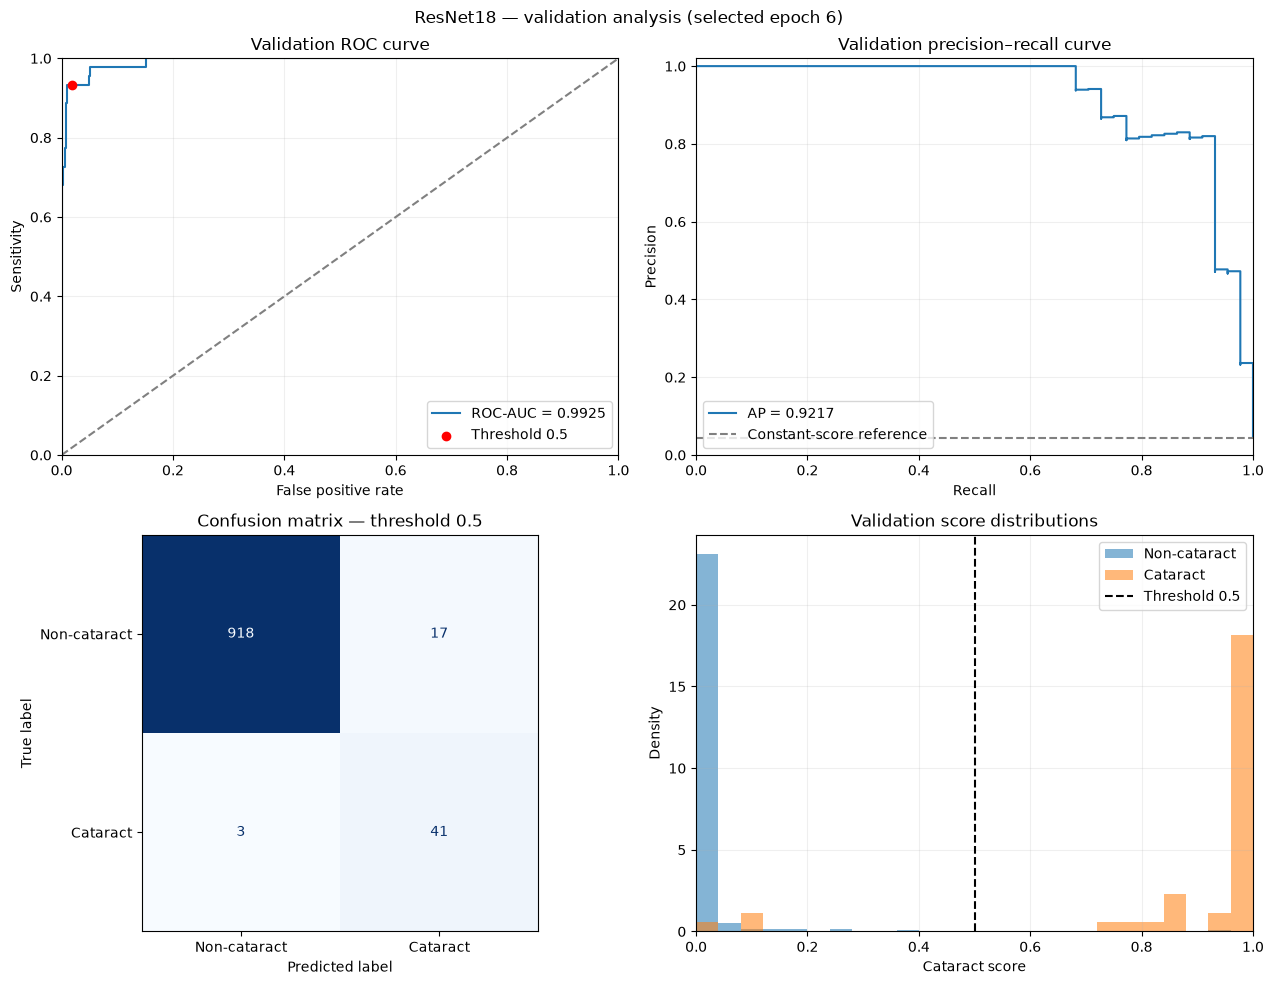

VALIDATION SUBGROUP RESULTS
                   group  images  patients  errors  sensitivity  false_positive_rate
                cataract      44        29       3     0.931818                  NaN
        healthy_negative     422       275       9          NaN             0.021327
other_condition_negative     513       318       8          NaN             0.015595

ERROR COUNTS
error_type
False positive    17
False negative     3

Saved analysis: C:\Users\Lenovo\OneDrive\Desktop\cataract-detection-odir\results\resnet18_seed42_04287aebf1_v1\validation_analysis
Test set remains unevaluated.


In [23]:
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_curve,
    precision_recall_curve,
    ConfusionMatrixDisplay,
)

labels = resnet_val["label"].astype(int).to_numpy()
scores = resnet_val["cataract_score"].to_numpy()
predicted = resnet_val["predicted_label"].astype(int).to_numpy()

fpr, tpr, roc_thresholds = roc_curve(labels, scores)
precision, recall, pr_thresholds = precision_recall_curve(
    labels, scores
)
matrix = confusion_matrix(labels, predicted, labels=[0, 1])
tn, fp, fn, tp = matrix.ravel()

# Save numerical curve data for later comparisons and the report.
pd.DataFrame({
    "false_positive_rate": fpr,
    "sensitivity": tpr,
    "threshold": roc_thresholds,
}).to_csv(RESNET_EVAL_DIR / "roc_points.csv", index=False)

pd.DataFrame({
    "recall": recall,
    "precision": precision,
    "threshold": np.r_[pr_thresholds, np.nan],
}).to_csv(RESNET_EVAL_DIR / "pr_points.csv", index=False)

pd.DataFrame(
    matrix,
    index=["True non-cataract", "True cataract"],
    columns=["Predicted non-cataract", "Predicted cataract"],
).to_csv(RESNET_EVAL_DIR / "confusion_matrix.csv")

# Four-panel validation figure.
fig, axes = plt.subplots(2, 2, figsize=(13, 10))

axes[0, 0].plot(
    fpr, tpr,
    label=f"ROC-AUC = {resnet_validation_metrics['roc_auc']:.4f}",
)
axes[0, 0].plot([0, 1], [0, 1], "--", color="gray")
axes[0, 0].scatter(
    fp / (fp + tn), tp / (tp + fn),
    color="red", label="Threshold 0.5", zorder=3,
)
axes[0, 0].set(
    title="Validation ROC curve",
    xlabel="False positive rate",
    ylabel="Sensitivity",
    xlim=(0, 1), ylim=(0, 1),
)
axes[0, 0].legend(loc="lower right")

axes[0, 1].step(
    recall, precision, where="post",
    label=f"AP = {resnet_validation_metrics['average_precision']:.4f}",
)
axes[0, 1].axhline(
    labels.mean(), linestyle="--", color="gray",
    label="Constant-score reference",
)
axes[0, 1].set(
    title="Validation precision–recall curve",
    xlabel="Recall", ylabel="Precision",
    xlim=(0, 1), ylim=(0, 1.02),
)
axes[0, 1].legend(loc="lower left")

ConfusionMatrixDisplay(
    matrix, display_labels=["Non-cataract", "Cataract"]
).plot(
    ax=axes[1, 0], cmap="Blues",
    colorbar=False, values_format="d",
)
axes[1, 0].set_title("Confusion matrix — threshold 0.5")

bins = np.linspace(0, 1, 26)
for label, name in [(0, "Non-cataract"), (1, "Cataract")]:
    axes[1, 1].hist(
        scores[labels == label],
        bins=bins, density=True, alpha=0.55, label=name,
    )

axes[1, 1].axvline(
    0.5, color="black", linestyle="--", label="Threshold 0.5"
)
axes[1, 1].set(
    title="Validation score distributions",
    xlabel="Cataract score", ylabel="Density", xlim=(0, 1),
)
axes[1, 1].legend()

for ax in [axes[0, 0], axes[0, 1], axes[1, 1]]:
    ax.grid(alpha=0.2)

fig.suptitle(
    f"ResNet18 — validation analysis "
    f"(selected epoch {resnet_checkpoint['epoch']})"
)
fig.tight_layout()
fig.savefig(
    RESNET_EVAL_DIR / "validation_overview.png",
    dpi=200, bbox_inches="tight",
)
plt.show()
plt.close(fig)

# Subgroup results: sensitivity for positives, FPR for negatives.
subgroup_records = []

for group in [
    "cataract", "healthy_negative", "other_condition_negative"
]:
    subset = resnet_val.loc[
        resnet_val["evaluation_group"].eq(group)
    ]

    positive = subset["label"].eq(1)
    negative = subset["label"].eq(0)

    true_positives = (
        positive & subset["predicted_label"].eq(1)
    ).sum()
    false_positives = (
        negative & subset["predicted_label"].eq(1)
    ).sum()

    subgroup_records.append({
        "group": group,
        "images": len(subset),
        "patients": subset["patient_id"].nunique(),
        "errors": int(
            subset["label"].ne(subset["predicted_label"]).sum()
        ),
        "sensitivity": (
            true_positives / positive.sum()
            if positive.sum() else np.nan
        ),
        "false_positive_rate": (
            false_positives / negative.sum()
            if negative.sum() else np.nan
        ),
    })

resnet_subgroup_metrics = pd.DataFrame(subgroup_records)
resnet_subgroup_metrics.to_csv(
    RESNET_EVAL_DIR / "subgroup_metrics.csv", index=False
)

resnet_errors = resnet_val.loc[
    resnet_val["label"].ne(resnet_val["predicted_label"])
].copy()

resnet_errors["error_type"] = np.where(
    resnet_errors["label"].eq(0),
    "False positive",
    "False negative",
)
resnet_errors.to_csv(
    RESNET_EVAL_DIR / "misclassified_images.csv", index=False
)

print("VALIDATION SUBGROUP RESULTS")
print(resnet_subgroup_metrics.to_string(index=False))

print("\nERROR COUNTS")
print(resnet_errors["error_type"].value_counts().to_string())

print("\nSaved analysis:", RESNET_EVAL_DIR)
print("Test set remains unevaluated.")

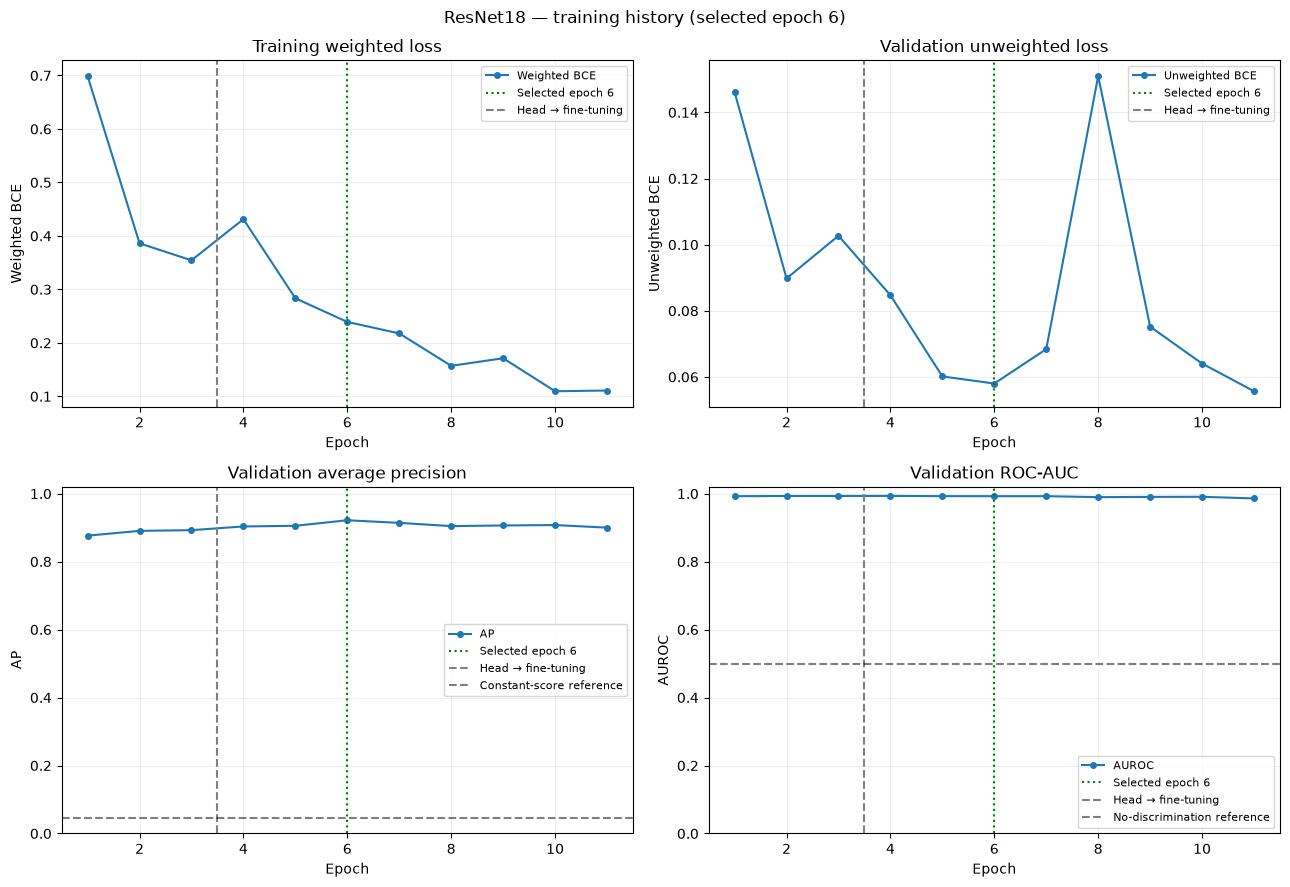

Completed epochs: 11
Selected epoch: 6
Saved curves: C:\Users\Lenovo\OneDrive\Desktop\cataract-detection-odir\results\resnet18_seed42_04287aebf1_v1\validation_analysis\training_curves.png

Training loss is weighted; validation loss is unweighted. Their absolute values are not directly comparable.

Section 15 complete. Test set remains unevaluated.


In [25]:
import pandas as pd
import matplotlib.pyplot as plt

# Load saved training history.
resnet_history = pd.read_csv(
    RESNET_RESULT_DIR / "training_history.csv"
).sort_values("epoch").reset_index(drop=True)

# Standardize the AUROC column name for plotting.
if "val_roc_auc" not in resnet_history.columns:
    resnet_history = resnet_history.rename(
        columns={"val_auroc": "val_roc_auc"}
    )

required_columns = {
    "epoch",
    "phase",
    "train_loss",
    "val_loss",
    "val_average_precision",
    "val_roc_auc",
}

missing_columns = required_columns - set(resnet_history.columns)

if missing_columns:
    raise ValueError(
        f"Missing history columns: {sorted(missing_columns)}\n"
        f"Available columns: {resnet_history.columns.tolist()}"
    )

if resnet_history.empty:
    raise ValueError("Training history is empty.")

if resnet_history["epoch"].duplicated().any():
    raise ValueError("Training history contains duplicate epochs.")

selected_epoch = int(resnet_checkpoint["epoch"])

if selected_epoch not in resnet_history["epoch"].values:
    raise ValueError("Selected epoch is missing from training history.")

# Plot weighted training loss and unweighted validation loss separately.
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

plot_settings = [
    ("train_loss", "Training weighted loss", "Weighted BCE"),
    ("val_loss", "Validation unweighted loss", "Unweighted BCE"),
    (
        "val_average_precision",
        "Validation average precision",
        "AP",
    ),
    ("val_roc_auc", "Validation ROC-AUC", "AUROC"),
]

fine_tune_epochs = resnet_history.loc[
    resnet_history["phase"].eq("fine_tune"), "epoch"
]

for ax, (column, title, ylabel) in zip(
    axes.flat, plot_settings
):
    ax.plot(
        resnet_history["epoch"],
        resnet_history[column],
        marker="o",
        markersize=4,
        label=ylabel,
    )

    ax.axvline(
        selected_epoch,
        color="green",
        linestyle=":",
        label=f"Selected epoch {selected_epoch}",
    )

    if not fine_tune_epochs.empty:
        ax.axvline(
            fine_tune_epochs.min() - 0.5,
            color="gray",
            linestyle="--",
            label="Head → fine-tuning",
        )

    if column == "val_average_precision":
        ax.axhline(
            resnet_val["label"].mean(),
            color="black",
            linestyle="--",
            alpha=0.5,
            label="Constant-score reference",
        )
        ax.set_ylim(0, 1.02)

    elif column == "val_roc_auc":
        ax.axhline(
            0.5,
            color="black",
            linestyle="--",
            alpha=0.5,
            label="No-discrimination reference",
        )
        ax.set_ylim(0, 1.02)

    ax.set(
        title=title,
        xlabel="Epoch",
        ylabel=ylabel,
    )
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)

fig.suptitle(
    f"ResNet18 — training history "
    f"(selected epoch {selected_epoch})"
)
fig.tight_layout()

RESNET_EVAL_DIR.mkdir(parents=True, exist_ok=True)
curve_path = RESNET_EVAL_DIR / "training_curves.png"

fig.savefig(
    curve_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

print("Completed epochs:", len(resnet_history))
print("Selected epoch:", selected_epoch)
print("Saved curves:", curve_path)
print(
    "\nTraining loss is weighted; validation loss is unweighted. "
    "Their absolute values are not directly comparable."
)
print("\nSection 15 complete. Test set remains unevaluated.")

## 16. EfficientNet-B0 Setup and Training

Train an ImageNet-pretrained EfficientNet-B0 for binary cataract detection.

Use the same cached images, augmentation, patient splits and weighted
training loss as ResNet18. Train the classification head for 3 epochs,
then fine-tune for up to 22 epochs. Select checkpoints using validation
average precision. Keep BatchNorm running statistics frozen.

The test set remains reserved for final evaluation.

In [26]:
import copy
import json
import torch
import torchvision
from torch import nn
from torchvision.models import (
    efficientnet_b0,
    EfficientNet_B0_Weights,
)

required_globals = [
    "resnet_config",
    "cached_train_df",
    "cached_val_df",
    "make_cached_data_loaders",
    "run_binary_epoch",
    "seed_everything",
]

missing = [
    name for name in required_globals
    if name not in globals()
]

if missing:
    raise RuntimeError(
        f"Required definitions are missing: {missing}. "
        "Restore the relevant setup cells before continuing."
    )

EFFNET_RUN_NAME = (
    f"efficientnet_b0_seed{SEED}_{COHORT_SHA256[:10]}_v1"
)
EFFNET_MODEL_DIR = PROJECT_ROOT / "models" / EFFNET_RUN_NAME
EFFNET_RESULT_DIR = PROJECT_ROOT / "results" / EFFNET_RUN_NAME

EFFNET_MODEL_DIR.mkdir(parents=True, exist_ok=True)
EFFNET_RESULT_DIR.mkdir(parents=True, exist_ok=True)

effnet_positive_count = int(
    cached_train_df["label"].eq(1).sum()
)
effnet_negative_count = int(
    cached_train_df["label"].eq(0).sum()
)

if min(effnet_positive_count, effnet_negative_count) == 0:
    raise ValueError("Training data must contain both classes.")

EFFNET_POSITIVE_WEIGHT = (
    effnet_negative_count / effnet_positive_count
)

effnet_config = copy.deepcopy(resnet_config)
effnet_config.update({
    "run_name": EFFNET_RUN_NAME,
    "architecture": "EfficientNetB0Cataract",
    "pretrained_weights": "IMAGENET1K_V1",
    "positive_loss_weight": EFFNET_POSITIVE_WEIGHT,
    "stochastic_depth_probability": 0.2,
    "torch_version": str(torch.__version__),
    "torchvision_version": str(torchvision.__version__),
})

config_path = EFFNET_RESULT_DIR / "config.json"

if config_path.exists():
    saved_config = json.loads(
        config_path.read_text(encoding="utf-8")
    )
    if saved_config != effnet_config:
        raise ValueError(
            "An existing EfficientNet run has different settings. "
            "Inspect its configuration before continuing."
        )
else:
    config_path.write_text(
        json.dumps(effnet_config, indent=2),
        encoding="utf-8",
    )

print("EFFICIENTNET-B0 CONFIGURATION")
print("Run:", EFFNET_RUN_NAME)
print("Device:", DEVICE)
print("Training images:", len(cached_train_df))
print("Validation images:", len(cached_val_df))
print("Positive loss weight:", round(EFFNET_POSITIVE_WEIGHT, 4))
print("Head epochs:", effnet_config["head_epochs"])
print("Maximum fine-tuning epochs:", effnet_config["fine_tune_epochs"])
print("Checkpoint selection: validation average precision")

EFFICIENTNET-B0 CONFIGURATION
Run: efficientnet_b0_seed42_04287aebf1_v1
Device: cuda
Training images: 4548
Validation images: 979
Positive loss weight: 21.5149
Head epochs: 3
Maximum fine-tuning epochs: 22
Checkpoint selection: validation average precision


In [27]:
class EfficientNetB0Cataract(nn.Module):
    def __init__(
        self,
        dropout=0.3,
        pretrained=True,
        stochastic_depth_probability=0.2,
    ):
        super().__init__()

        weights = (
            EfficientNet_B0_Weights.IMAGENET1K_V1
            if pretrained else None
        )

        self.backbone = efficientnet_b0(
            weights=weights,
            stochastic_depth_prob=stochastic_depth_probability,
        )

        feature_count = (
            self.backbone.classifier[1].in_features
        )
        self.backbone.classifier = nn.Identity()

        self.classifier = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(feature_count, 1),
        )

        self.training_phase = "head"
        self.set_phase("head")

    def set_phase(self, phase):
        if phase not in {"head", "fine_tune"}:
            raise ValueError(f"Unknown training phase: {phase}")

        self.training_phase = phase

        for parameter in self.backbone.parameters():
            parameter.requires_grad = phase == "fine_tune"

        for parameter in self.classifier.parameters():
            parameter.requires_grad = True

        self.train(self.training)

    def train(self, mode=True):
        super().train(mode)

        if mode:
            if self.training_phase == "head":
                self.backbone.eval()
            else:
                # Freeze running statistics while allowing
                # learnable BatchNorm parameters to update.
                for module in self.backbone.modules():
                    if isinstance(module, nn.BatchNorm2d):
                        module.eval()

        return self

    def forward(self, images):
        features = self.backbone(images)
        return self.classifier(features).squeeze(1)


seed_everything(SEED)

effnet_model = EfficientNetB0Cataract(
    dropout=effnet_config["dropout"],
    pretrained=True,
    stochastic_depth_probability=effnet_config[
        "stochastic_depth_probability"
    ],
).to(DEVICE)

print("Model: EfficientNetB0Cataract")
print(
    "Total parameters:",
    f"{sum(p.numel() for p in effnet_model.parameters()):,}",
)
print(
    "Initially trainable parameters:",
    f"{sum(p.numel() for p in effnet_model.parameters() if p.requires_grad):,}",
)

Model: EfficientNetB0Cataract
Total parameters: 4,008,829
Initially trainable parameters: 1,281


In [28]:
def configure_effnet_phase(model, phase):
    model.set_phase(phase)

    if phase == "head":
        parameter_groups = [{
            "params": list(model.classifier.parameters()),
            "lr": effnet_config["head_learning_rate"],
            "name": "classifier",
        }]
    else:
        parameter_groups = [
            {
                "params": list(model.backbone.parameters()),
                "lr": effnet_config[
                    "fine_tune_backbone_learning_rate"
                ],
                "name": "backbone",
            },
            {
                "params": list(model.classifier.parameters()),
                "lr": effnet_config[
                    "fine_tune_head_learning_rate"
                ],
                "name": "classifier",
            },
        ]

    optimizer = torch.optim.AdamW(
        parameter_groups,
        weight_decay=effnet_config["weight_decay"],
    )

    scheduler_settings = effnet_config["scheduler"]

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode=scheduler_settings["mode"],
        factor=scheduler_settings["factor"],
        patience=scheduler_settings["patience"],
        min_lr=scheduler_settings["min_lr"],
    )

    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=DEVICE.type == "cuda",
    )

    return optimizer, scheduler, scaler


effnet_train_criterion = nn.BCEWithLogitsLoss(
    pos_weight=torch.tensor(
        [EFFNET_POSITIVE_WEIGHT],
        dtype=torch.float32,
        device=DEVICE,
    )
)
effnet_eval_criterion = nn.BCEWithLogitsLoss()

effnet_optimizer, effnet_scheduler, effnet_scaler = (
    configure_effnet_phase(effnet_model, "head")
)

effnet_train_loader, effnet_val_loader = (
    make_cached_data_loaders(cached_train_df)
)

effnet_model.train()

assert not effnet_model.backbone.training
assert all(
    not parameter.requires_grad
    for parameter in effnet_model.backbone.parameters()
)
assert all(
    parameter.requires_grad
    for parameter in effnet_model.classifier.parameters()
)

# Check a validation batch without updating any weights.
effnet_probe = next(iter(effnet_val_loader))
effnet_model.eval()

with torch.no_grad():
    effnet_probe_output = effnet_model(
        effnet_probe["image"].to(DEVICE)
    )

assert effnet_probe_output.shape == effnet_probe["label"].shape
assert torch.isfinite(effnet_probe_output).all()

# Fresh loaders for the training cell.
effnet_train_loader, effnet_val_loader = (
    make_cached_data_loaders(cached_train_df)
)

del effnet_probe, effnet_probe_output

print("EFFICIENTNET-B0 FORWARD-PASS CHECK PASSED")
print("Initial phase:", effnet_model.training_phase)
print("Backbone frozen: True")
print("Head learning rate:", effnet_config["head_learning_rate"])
print("No EfficientNet-B0 training has started yet.")

EFFICIENTNET-B0 FORWARD-PASS CHECK PASSED
Initial phase: head
Backbone frozen: True
Head learning rate: 0.001
No EfficientNet-B0 training has started yet.


In [29]:
import json
import time
import numpy as np
import pandas as pd
import torch


def train_effnet_b0():
    model = effnet_model
    config = effnet_config

    latest_path = EFFNET_MODEL_DIR / "latest_training.pth"
    best_path = EFFNET_MODEL_DIR / "best.pth"
    history_path = EFFNET_RESULT_DIR / "training_history.csv"
    summary_path = EFFNET_RESULT_DIR / "training_summary.json"

    head_epochs = int(config["head_epochs"])
    total_epochs = head_epochs + int(config["fine_tune_epochs"])
    patience = int(config["fine_tune_early_stopping_patience"])

    train_loader, val_loader = make_cached_data_loaders(
        cached_train_df
    )

    def atomic_torch_save(payload, destination):
        temporary = destination.with_suffix(".tmp")
        torch.save(payload, temporary)
        temporary.replace(destination)

    def atomic_json_save(payload, destination):
        temporary = destination.with_suffix(".tmp")
        temporary.write_text(
            json.dumps(payload, indent=2),
            encoding="utf-8",
        )
        temporary.replace(destination)

    def cpu_model_state():
        return {
            name: value.detach().cpu().clone()
            for name, value in model.state_dict().items()
        }

    history = []
    phase = "head"
    phase_best_ap = float("-inf")
    bad_epochs = 0
    best_ap = float("-inf")
    best_epoch = None
    best_phase = None
    best_checkpoint = None
    best_predictions = None
    completed_epoch = 0
    training_complete = False

    # Restore the complete state of the last completed epoch.
    if latest_path.exists():
        saved = torch.load(
            latest_path,
            map_location="cpu",
            weights_only=True,
        )

        if saved["config"] != config:
            raise ValueError(
                "Saved checkpoint configuration differs from this run."
            )

        phase = saved["phase"]
        model.set_phase(phase)
        model.load_state_dict(saved["model_state_dict"])
        model.to(DEVICE)

        optimizer, scheduler, scaler = configure_effnet_phase(
            model, phase
        )
        optimizer.load_state_dict(saved["optimizer_state_dict"])
        scheduler.load_state_dict(saved["scheduler_state_dict"])
        scaler.load_state_dict(saved["scaler_state_dict"])

        history = saved["history"]
        completed_epoch = int(saved["completed_epoch"])
        phase_best_ap = saved["phase_best_ap"]
        bad_epochs = saved["bad_epochs"]

        best_ap = saved["best_ap"]
        best_epoch = saved["best_epoch"]
        best_phase = saved["best_phase"]
        best_checkpoint = saved["best_checkpoint"]
        best_predictions = saved["best_predictions"]
        training_complete = saved["training_complete"]

        if len(history) != completed_epoch:
            raise ValueError("Saved epoch count and history disagree.")

        torch.set_rng_state(saved["torch_rng_state"])
        train_loader.generator.set_state(
            saved["loader_generator_state"]
        )

        if DEVICE.type == "cuda" and saved["cuda_rng_states"]:
            torch.cuda.set_rng_state_all(saved["cuda_rng_states"])

        del saved
        print("Restored:", latest_path.name)

    else:
        if best_path.exists() or history_path.exists():
            raise RuntimeError(
                "Existing results were found without a resumable "
                "checkpoint. Inspect the run folder first."
            )

        seed_everything(SEED)
        model.to(DEVICE)
        optimizer, scheduler, scaler = configure_effnet_phase(
            model, "head"
        )
        print("Starting a new EfficientNet-B0 run.")

    optimizer.zero_grad(set_to_none=True)

    def save_boundary(complete=False):
        # Include the selected checkpoint and its predictions so that
        # exported files can be recovered consistently after a crash.
        payload = {
            "checkpoint_kind": "epoch_boundary",
            "config": config,
            "model_state_dict": cpu_model_state(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "scaler_state_dict": scaler.state_dict(),
            "phase": phase,
            "completed_epoch": completed_epoch,
            "history": history,
            "phase_best_ap": phase_best_ap,
            "bad_epochs": bad_epochs,
            "best_ap": best_ap,
            "best_epoch": best_epoch,
            "best_phase": best_phase,
            "best_checkpoint": best_checkpoint,
            "best_predictions": best_predictions,
            "training_complete": complete,
            "torch_rng_state": torch.get_rng_state(),
            "cuda_rng_states": (
                torch.cuda.get_rng_state_all()
                if DEVICE.type == "cuda" else []
            ),
            "loader_generator_state": (
                train_loader.generator.get_state()
            ),
        }
        atomic_torch_save(payload, latest_path)

    def export_results():
        if history:
            temporary = history_path.with_suffix(".tmp")
            pd.DataFrame(history).to_csv(temporary, index=False)
            temporary.replace(history_path)

        if best_checkpoint is not None:
            atomic_torch_save(best_checkpoint, best_path)

            prediction_path = (
                EFFNET_RESULT_DIR / "validation_predictions.csv"
            )
            temporary = prediction_path.with_suffix(".tmp")

            pd.DataFrame(best_predictions).to_csv(
                temporary, index=False
            )
            temporary.replace(prediction_path)

    # Recover any exports missing after an interrupted file write.
    export_results()

    # Save epoch zero before any training updates.
    if not latest_path.exists():
        save_boundary(complete=False)

    print("Run:", EFFNET_RUN_NAME)
    print("Next epoch:", completed_epoch + 1)
    print("Maximum total epochs:", total_epochs)

    interrupted = False

    stopping_condition_met = (
        training_complete
        or completed_epoch >= total_epochs
        or (phase == "fine_tune" and bad_epochs >= patience)
    )

    if stopping_condition_met:
        print("Training has already met its stopping condition.")

    else:
        try:
            for epoch in range(completed_epoch + 1, total_epochs + 1):
                desired_phase = (
                    "head" if epoch <= head_epochs else "fine_tune"
                )

                if desired_phase != phase:
                    if best_checkpoint is None:
                        raise RuntimeError(
                            "No head checkpoint is available."
                        )

                    # At this transition, the overall best checkpoint
                    # is the best checkpoint from head training.
                    model.load_state_dict(
                        best_checkpoint["model_state_dict"]
                    )
                    phase = desired_phase

                    optimizer, scheduler, scaler = (
                        configure_effnet_phase(model, phase)
                    )
                    phase_best_ap = float("-inf")
                    bad_epochs = 0

                    print(
                        "\nFine-tuning starts from the best "
                        "head-training checkpoint."
                    )

                phase_epoch = (
                    epoch if phase == "head"
                    else epoch - head_epochs
                )

                learning_rates = {
                    f"lr_{group['name']}": float(group["lr"])
                    for group in optimizer.param_groups
                }

                print(
                    f"\nEpoch {epoch}/{total_epochs} | "
                    f"Phase: {phase} | "
                    f"Phase epoch: {phase_epoch}",
                    flush=True,
                )

                started = time.perf_counter()

                train_metrics, _ = run_binary_epoch(
                    model,
                    train_loader,
                    effnet_train_criterion,
                    optimizer,
                    scaler,
                )

                val_metrics, predictions = run_binary_epoch(
                    model,
                    val_loader,
                    effnet_eval_criterion,
                )

                current_ap = float(
                    val_metrics["average_precision"]
                )

                if not np.isfinite(current_ap):
                    raise ValueError("Validation AP is not finite.")

                phase_improved = current_ap > phase_best_ap
                global_improved = current_ap > best_ap

                if global_improved:
                    ordered = (
                        predictions.sort_values("row_index")
                        .reset_index(drop=True)
                    )

                    if not np.array_equal(
                        ordered["row_index"].to_numpy(),
                        np.arange(len(val_df)),
                    ):
                        raise ValueError(
                            "Validation prediction rows do not align."
                        )

                    metadata = (
                        val_df[
                            [
                                "patient_id",
                                "image_path",
                                "evaluation_group",
                                "label",
                            ]
                        ]
                        .reset_index(drop=True)
                        .copy()
                    )

                    if not np.array_equal(
                        ordered["true_label"].astype(int).to_numpy(),
                        metadata["label"].astype(int).to_numpy(),
                    ):
                        raise ValueError(
                            "Validation labels do not align."
                        )

                    aligned = pd.concat(
                        [ordered, metadata], axis=1
                    )

                    best_ap = current_ap
                    best_epoch = epoch
                    best_phase = phase

                    best_checkpoint = {
                        "model_state_dict": cpu_model_state(),
                        "config": config,
                        "epoch": epoch,
                        "phase": phase,
                        "validation_metrics": val_metrics,
                    }

                    best_predictions = aligned.to_dict(
                        orient="list"
                    )

                if phase_improved:
                    phase_best_ap = current_ap
                    bad_epochs = 0
                else:
                    bad_epochs += 1

                scheduler.step(current_ap)

                epoch_seconds = time.perf_counter() - started

                record = {
                    "epoch": epoch,
                    "phase": phase,
                    "phase_epoch": phase_epoch,
                    "epoch_seconds": epoch_seconds,
                    "global_checkpoint_improved": global_improved,
                    **learning_rates,
                    **{
                        f"train_{key}": value
                        for key, value in train_metrics.items()
                    },
                    **{
                        f"val_{key}": value
                        for key, value in val_metrics.items()
                    },
                }

                history.append(record)
                completed_epoch = epoch

                # Save before printing or exporting other results.
                save_boundary(complete=False)
                export_results()

                validation_auc = val_metrics.get(
                    "auroc",
                    val_metrics.get("roc_auc", float("nan")),
                )

                print(
                    f"Train weighted loss: "
                    f"{train_metrics['loss']:.4f} | "
                    f"Val unweighted loss: "
                    f"{val_metrics['loss']:.4f}"
                )
                print(
                    f"Val AP: {current_ap:.4f} | "
                    f"AUROC: {validation_auc:.4f} | "
                    f"Sensitivity: "
                    f"{val_metrics['sensitivity']:.3f} | "
                    f"Specificity: "
                    f"{val_metrics['specificity']:.3f}"
                )
                print(
                    f"Epoch time: {epoch_seconds:.1f}s | "
                    f"Overall best AP: {best_ap:.4f}",
                    flush=True,
                )

                if phase == "fine_tune" and bad_epochs >= patience:
                    print(
                        "\nEarly stopping: no fine-tuning AP "
                        f"improvement for {patience} epochs."
                    )
                    break

        except KeyboardInterrupt:
            interrupted = True
            print(
                "\nTraining interrupted. The last completed epoch "
                "is saved in latest_training.pth."
            )
            print(
                "Rerun this cell to restore that checkpoint. "
                "Any unfinished epoch will be repeated."
            )

    if not interrupted:
        training_complete = True
        save_boundary(complete=True)
        export_results()

    summary = {
        "run_name": EFFNET_RUN_NAME,
        "training_complete": bool(training_complete),
        "epochs_completed": int(completed_epoch),
        "best_epoch": best_epoch,
        "best_phase": best_phase,
        "best_validation_average_precision": (
            float(best_ap) if best_epoch is not None else None
        ),
        "checkpoint": (
            best_path.relative_to(PROJECT_ROOT).as_posix()
            if best_epoch is not None else None
        ),
    }

    atomic_json_save(summary, summary_path)

    print(
        "\nEFFICIENTNET-B0 TRAINING COMPLETE"
        if training_complete
        else "\nEFFICIENTNET-B0 TRAINING PAUSED"
    )
    print(json.dumps(summary, indent=2))

    return summary


effnet_training_summary = train_effnet_b0()

Starting a new EfficientNet-B0 run.
Run: efficientnet_b0_seed42_04287aebf1_v1
Next epoch: 1
Maximum total epochs: 25

Epoch 1/25 | Phase: head | Phase epoch: 1
  Training: batch 100/285
  Training: batch 200/285
  Training: batch 285/285
  Validation: batch 30/62
  Validation: batch 60/62
  Validation: batch 62/62
Train weighted loss: 0.4646 | Val unweighted loss: 0.1252
Val AP: 0.9093 | AUROC: 0.9918 | Sensitivity: 0.909 | Specificity: 0.956
Epoch time: 31.2s | Overall best AP: 0.9093

Epoch 2/25 | Phase: head | Phase epoch: 2
  Training: batch 100/285
  Training: batch 200/285
  Training: batch 285/285
  Validation: batch 30/62
  Validation: batch 60/62
  Validation: batch 62/62
Train weighted loss: 0.2965 | Val unweighted loss: 0.0904
Val AP: 0.9126 | AUROC: 0.9923 | Sensitivity: 0.886 | Specificity: 0.972
Epoch time: 26.3s | Overall best AP: 0.9126

Epoch 3/25 | Phase: head | Phase epoch: 3
  Training: batch 100/285
  Training: batch 200/285
  Training: batch 285/285
  Validation: 

## 17. EfficientNet-B0 Validation and Error Analysis

Evaluate the checkpoint selected using validation average precision.
Calculate classification metrics at threshold 0.5, inspect errors,
and generate validation plots.

The test set remains reserved for final evaluation.

In [30]:
import json
import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    confusion_matrix,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)

# Confirm that training has finished.
effnet_summary = json.loads(
    (EFFNET_RESULT_DIR / "training_summary.json").read_text(
        encoding="utf-8"
    )
)

if not effnet_summary["training_complete"]:
    raise RuntimeError("Finish or resume EfficientNet-B0 training first.")

# Load the selected checkpoint.
effnet_checkpoint = torch.load(
    EFFNET_MODEL_DIR / "best.pth",
    map_location="cpu",
    weights_only=True,
)

if effnet_checkpoint["config"] != effnet_config:
    raise ValueError("Checkpoint configuration does not match this run.")

effnet_model.set_phase(effnet_checkpoint["phase"])
effnet_model.load_state_dict(
    effnet_checkpoint["model_state_dict"]
)
effnet_model.to(DEVICE)
effnet_model.eval()

# Verify validation image identities and row order.
identity_columns = [
    "patient_id", "image_path", "evaluation_group", "label"
]

pd.testing.assert_frame_equal(
    cached_val_df[identity_columns].reset_index(drop=True),
    val_df[identity_columns].reset_index(drop=True),
    check_dtype=False,
)

# Run validation inference.
_, effnet_validation_loader = make_cached_data_loaders(
    cached_train_df
)

_, effnet_predictions = run_binary_epoch(
    effnet_model,
    effnet_validation_loader,
    effnet_eval_criterion,
)

effnet_predictions = (
    effnet_predictions
    .sort_values("row_index")
    .reset_index(drop=True)
)

if not np.array_equal(
    effnet_predictions["row_index"].to_numpy(),
    np.arange(len(val_df)),
):
    raise ValueError("Validation predictions do not cover each row once.")

effnet_val = val_df.reset_index(drop=True).copy()
effnet_val.insert(0, "row_index", np.arange(len(effnet_val)))

if not np.array_equal(
    effnet_predictions["true_label"].astype(int).to_numpy(),
    effnet_val["label"].astype(int).to_numpy(),
):
    raise ValueError("Prediction labels do not match the validation manifest.")

effnet_val["cataract_score"] = (
    effnet_predictions["cataract_score"].to_numpy()
)

effnet_y_true = effnet_val["label"].astype(int).to_numpy()
effnet_y_score = effnet_val["cataract_score"].to_numpy()

if (
    not np.isfinite(effnet_y_score).all()
    or (effnet_y_score < 0).any()
    or (effnet_y_score > 1).any()
):
    raise ValueError("Validation scores must be finite and between 0 and 1.")

effnet_val["predicted_label"] = (
    effnet_y_score >= 0.5
).astype(int)

effnet_y_pred = effnet_val["predicted_label"].to_numpy()

tn, fp, fn, tp = confusion_matrix(
    effnet_y_true, effnet_y_pred, labels=[0, 1]
).ravel()

effnet_validation_metrics = {
    "model": "EfficientNet-B0",
    "selected_epoch": int(effnet_checkpoint["epoch"]),
    "selected_phase": effnet_checkpoint["phase"],
    "threshold": 0.5,
    "images": len(effnet_y_true),
    "average_precision": average_precision_score(
        effnet_y_true, effnet_y_score
    ),
    "roc_auc": roc_auc_score(effnet_y_true, effnet_y_score),
    "accuracy": accuracy_score(effnet_y_true, effnet_y_pred),
    "balanced_accuracy": balanced_accuracy_score(
        effnet_y_true, effnet_y_pred
    ),
    "precision": precision_score(
        effnet_y_true, effnet_y_pred, zero_division=0
    ),
    "sensitivity": recall_score(
        effnet_y_true, effnet_y_pred, zero_division=0
    ),
    "specificity": tn / (tn + fp),
    "f1": f1_score(
        effnet_y_true, effnet_y_pred, zero_division=0
    ),
    "tn": int(tn),
    "fp": int(fp),
    "fn": int(fn),
    "tp": int(tp),
}

# Confirm that inference reproduces the selected validation AP.
if not np.isclose(
    effnet_validation_metrics["average_precision"],
    effnet_summary["best_validation_average_precision"],
    atol=1e-6,
    rtol=0,
):
    raise ValueError(
        "Recomputed validation AP differs from the saved best result."
    )

EFFNET_EVAL_DIR = EFFNET_RESULT_DIR / "validation_analysis"
EFFNET_EVAL_DIR.mkdir(parents=True, exist_ok=True)

effnet_val.to_csv(
    EFFNET_EVAL_DIR / "validation_predictions.csv",
    index=False,
)

pd.DataFrame([effnet_validation_metrics]).to_csv(
    EFFNET_EVAL_DIR / "validation_metrics.csv",
    index=False,
)

print("EFFICIENTNET-B0 VALIDATION")
print(pd.Series(effnet_validation_metrics).to_string())
print("\nSaved analysis:", EFFNET_EVAL_DIR)
print("Test set remains unevaluated.")

  Validation: batch 30/62
  Validation: batch 60/62
  Validation: batch 62/62
EFFICIENTNET-B0 VALIDATION
model                EfficientNet-B0
selected_epoch                     5
selected_phase             fine_tune
threshold                        0.5
images                           979
average_precision           0.925897
roc_auc                     0.992635
accuracy                    0.977528
balanced_accuracy           0.934091
precision                   0.696429
sensitivity                 0.886364
specificity                 0.981818
f1                              0.78
tn                               918
fp                                17
fn                                 5
tp                                39

Saved analysis: C:\Users\Lenovo\OneDrive\Desktop\cataract-detection-odir\results\efficientnet_b0_seed42_04287aebf1_v1\validation_analysis
Test set remains unevaluated.


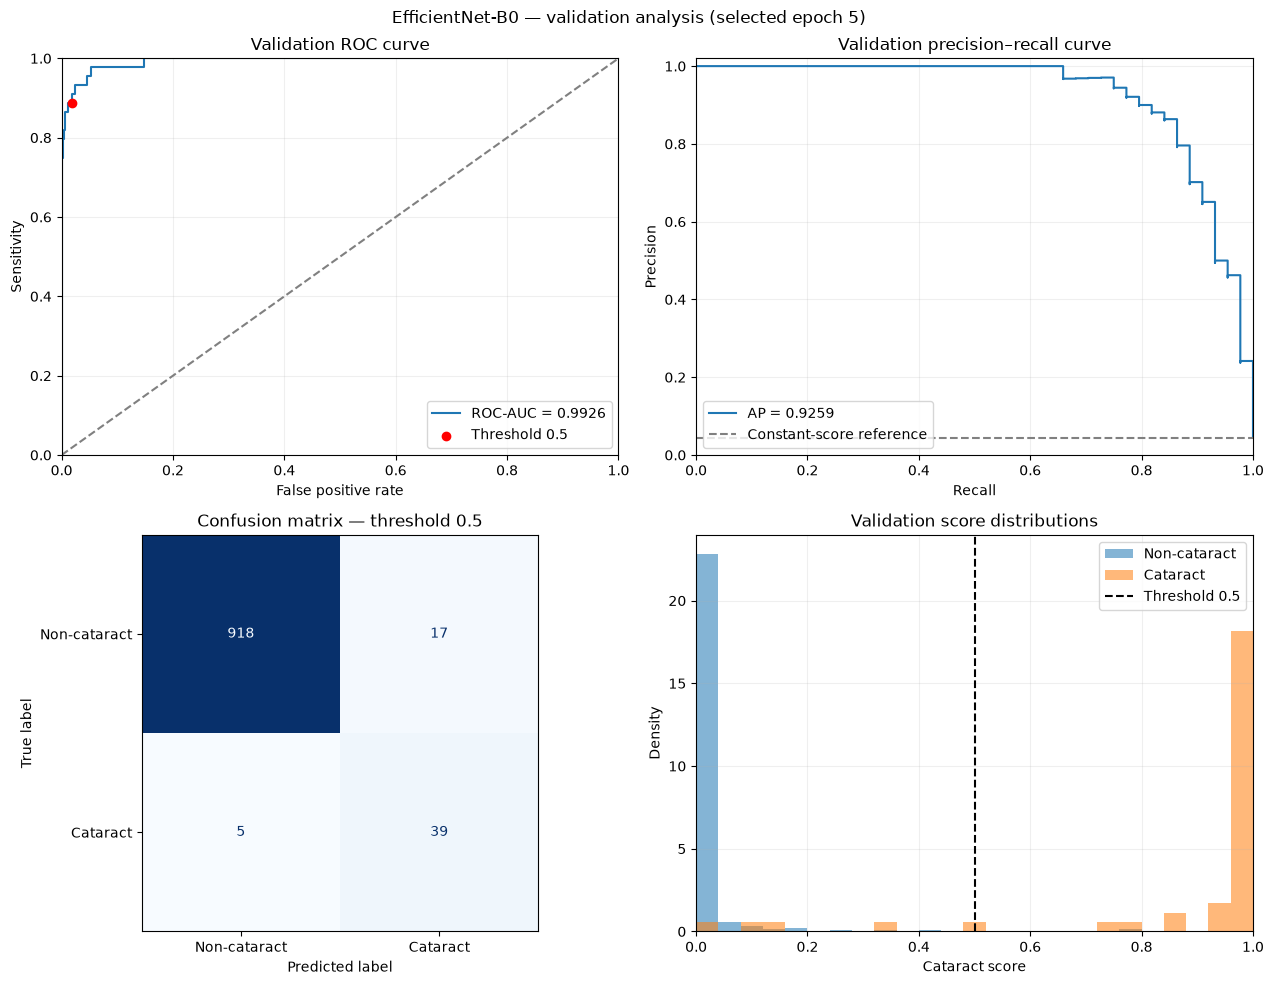

VALIDATION SUBGROUP RESULTS
                   group  images  patients  errors  sensitivity  false_positive_rate
                cataract      44        29       5     0.886364                  NaN
        healthy_negative     422       275       9          NaN             0.021327
other_condition_negative     513       318       8          NaN             0.015595

ERROR COUNTS
error_type
False positive    17
False negative     5

Saved analysis: C:\Users\Lenovo\OneDrive\Desktop\cataract-detection-odir\results\efficientnet_b0_seed42_04287aebf1_v1\validation_analysis
Test set remains unevaluated.


In [31]:
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_curve,
    precision_recall_curve,
    ConfusionMatrixDisplay,
)

labels = effnet_val["label"].astype(int).to_numpy()
scores = effnet_val["cataract_score"].to_numpy()
predicted = effnet_val["predicted_label"].astype(int).to_numpy()

fpr, tpr, roc_thresholds = roc_curve(labels, scores)
precision, recall, pr_thresholds = precision_recall_curve(
    labels, scores
)
matrix = confusion_matrix(labels, predicted, labels=[0, 1])
tn, fp, fn, tp = matrix.ravel()

# Save numerical results for later comparisons.
pd.DataFrame({
    "false_positive_rate": fpr,
    "sensitivity": tpr,
    "threshold": roc_thresholds,
}).to_csv(EFFNET_EVAL_DIR / "roc_points.csv", index=False)

pd.DataFrame({
    "recall": recall,
    "precision": precision,
    "threshold": np.r_[pr_thresholds, np.nan],
}).to_csv(EFFNET_EVAL_DIR / "pr_points.csv", index=False)

pd.DataFrame(
    matrix,
    index=["True non-cataract", "True cataract"],
    columns=["Predicted non-cataract", "Predicted cataract"],
).to_csv(EFFNET_EVAL_DIR / "confusion_matrix.csv")

fig, axes = plt.subplots(2, 2, figsize=(13, 10))

axes[0, 0].plot(
    fpr, tpr,
    label=f"ROC-AUC = {effnet_validation_metrics['roc_auc']:.4f}",
)
axes[0, 0].plot([0, 1], [0, 1], "--", color="gray")
axes[0, 0].scatter(
    fp / (fp + tn), tp / (tp + fn),
    color="red", label="Threshold 0.5", zorder=3,
)
axes[0, 0].set(
    title="Validation ROC curve",
    xlabel="False positive rate", ylabel="Sensitivity",
    xlim=(0, 1), ylim=(0, 1),
)
axes[0, 0].legend(loc="lower right")

axes[0, 1].step(
    recall, precision, where="post",
    label=f"AP = {effnet_validation_metrics['average_precision']:.4f}",
)
axes[0, 1].axhline(
    labels.mean(), linestyle="--", color="gray",
    label="Constant-score reference",
)
axes[0, 1].set(
    title="Validation precision–recall curve",
    xlabel="Recall", ylabel="Precision",
    xlim=(0, 1), ylim=(0, 1.02),
)
axes[0, 1].legend(loc="lower left")

ConfusionMatrixDisplay(
    matrix, display_labels=["Non-cataract", "Cataract"]
).plot(
    ax=axes[1, 0], cmap="Blues",
    colorbar=False, values_format="d",
)
axes[1, 0].set_title("Confusion matrix — threshold 0.5")

for label, name in [(0, "Non-cataract"), (1, "Cataract")]:
    axes[1, 1].hist(
        scores[labels == label],
        bins=np.linspace(0, 1, 26),
        density=True, alpha=0.55, label=name,
    )

axes[1, 1].axvline(
    0.5, color="black", linestyle="--", label="Threshold 0.5"
)
axes[1, 1].set(
    title="Validation score distributions",
    xlabel="Cataract score", ylabel="Density", xlim=(0, 1),
)
axes[1, 1].legend()

for ax in [axes[0, 0], axes[0, 1], axes[1, 1]]:
    ax.grid(alpha=0.2)

fig.suptitle(
    "EfficientNet-B0 — validation analysis "
    f"(selected epoch {effnet_checkpoint['epoch']})"
)
fig.tight_layout()
fig.savefig(
    EFFNET_EVAL_DIR / "validation_overview.png",
    dpi=200, bbox_inches="tight",
)
plt.show()
plt.close(fig)

# Calculate subgroup results.
subgroup_records = []

for group in [
    "cataract", "healthy_negative", "other_condition_negative"
]:
    subset = effnet_val.loc[
        effnet_val["evaluation_group"].eq(group)
    ]
    positive = subset["label"].eq(1)
    negative = subset["label"].eq(0)

    subgroup_records.append({
        "group": group,
        "images": len(subset),
        "patients": subset["patient_id"].nunique(),
        "errors": int(
            subset["label"].ne(subset["predicted_label"]).sum()
        ),
        "sensitivity": (
            (positive & subset["predicted_label"].eq(1)).sum()
            / positive.sum()
            if positive.sum() else np.nan
        ),
        "false_positive_rate": (
            (negative & subset["predicted_label"].eq(1)).sum()
            / negative.sum()
            if negative.sum() else np.nan
        ),
    })

effnet_subgroup_metrics = pd.DataFrame(subgroup_records)
effnet_subgroup_metrics.to_csv(
    EFFNET_EVAL_DIR / "subgroup_metrics.csv", index=False
)

effnet_errors = effnet_val.loc[
    effnet_val["label"].ne(effnet_val["predicted_label"])
].copy()

effnet_errors["error_type"] = np.where(
    effnet_errors["label"].eq(0),
    "False positive", "False negative",
)
effnet_errors.to_csv(
    EFFNET_EVAL_DIR / "misclassified_images.csv", index=False
)

print("VALIDATION SUBGROUP RESULTS")
print(effnet_subgroup_metrics.to_string(index=False))
print("\nERROR COUNTS")
print(effnet_errors["error_type"].value_counts().to_string())
print("\nSaved analysis:", EFFNET_EVAL_DIR)
print("Test set remains unevaluated.")

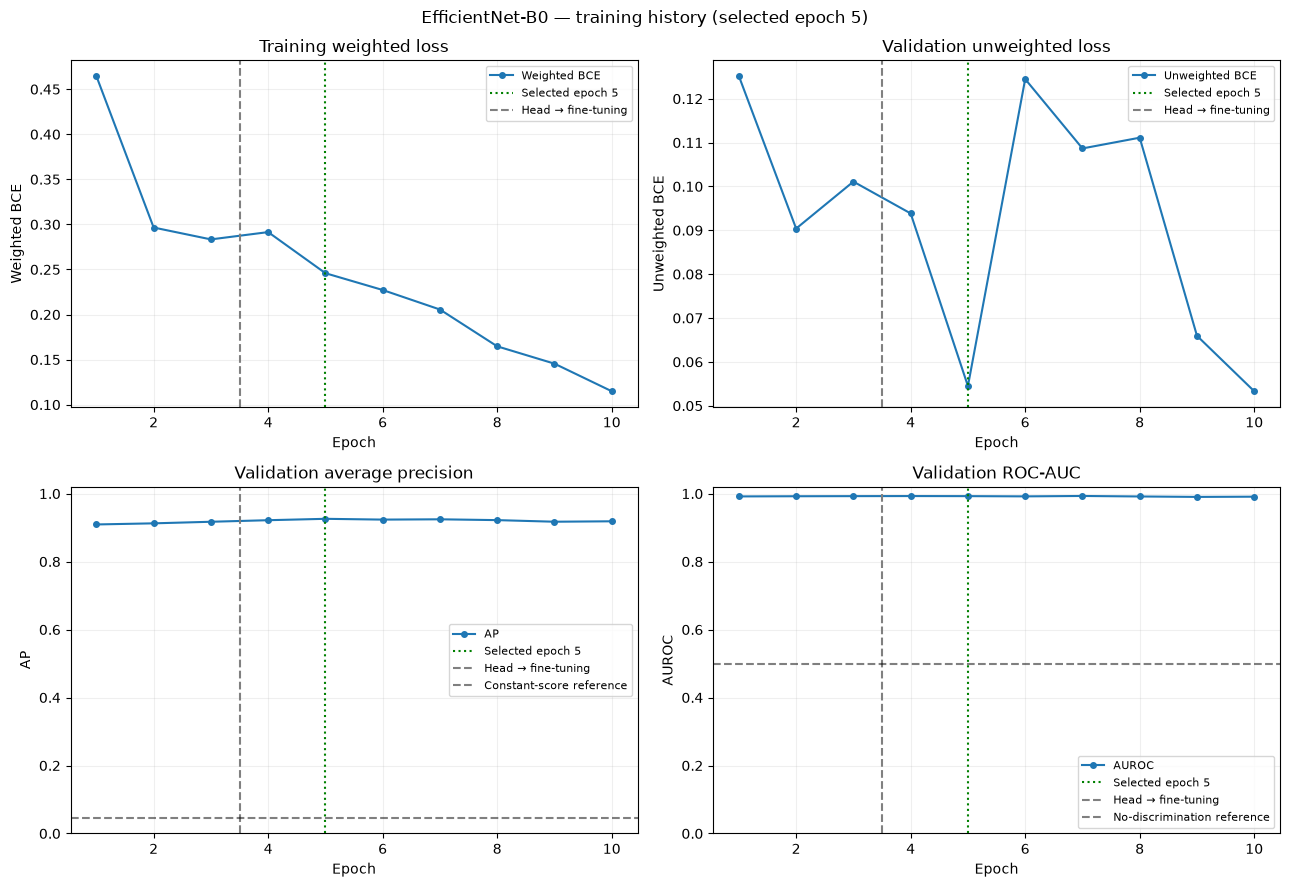

Completed epochs: 10
Selected epoch: 5
Saved curves: C:\Users\Lenovo\OneDrive\Desktop\cataract-detection-odir\results\efficientnet_b0_seed42_04287aebf1_v1\validation_analysis\training_curves.png
Training loss is weighted; validation loss is unweighted. Their absolute values are not directly comparable.

Section 17 complete. Test set remains unevaluated.


In [32]:
effnet_history = pd.read_csv(
    EFFNET_RESULT_DIR / "training_history.csv"
).sort_values("epoch").reset_index(drop=True)

if "val_roc_auc" not in effnet_history.columns:
    effnet_history = effnet_history.rename(
        columns={"val_auroc": "val_roc_auc"}
    )

required_columns = {
    "epoch", "phase", "train_loss", "val_loss",
    "val_average_precision", "val_roc_auc",
}
missing = required_columns - set(effnet_history.columns)

if missing:
    raise ValueError(
        f"Missing columns: {sorted(missing)}\n"
        f"Available columns: {effnet_history.columns.tolist()}"
    )

if effnet_history.empty or effnet_history["epoch"].duplicated().any():
    raise ValueError("Training history is empty or has duplicate epochs.")

selected_epoch = int(effnet_checkpoint["epoch"])

if selected_epoch not in effnet_history["epoch"].values:
    raise ValueError("Selected epoch is missing from training history.")

fine_epochs = effnet_history.loc[
    effnet_history["phase"].eq("fine_tune"), "epoch"
]

plot_settings = [
    ("train_loss", "Training weighted loss", "Weighted BCE"),
    ("val_loss", "Validation unweighted loss", "Unweighted BCE"),
    ("val_average_precision", "Validation average precision", "AP"),
    ("val_roc_auc", "Validation ROC-AUC", "AUROC"),
]

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for ax, (column, title, ylabel) in zip(axes.flat, plot_settings):
    ax.plot(
        effnet_history["epoch"], effnet_history[column],
        marker="o", markersize=4, label=ylabel,
    )
    ax.axvline(
        selected_epoch, color="green", linestyle=":",
        label=f"Selected epoch {selected_epoch}",
    )

    if not fine_epochs.empty:
        ax.axvline(
            fine_epochs.min() - 0.5,
            color="gray", linestyle="--",
            label="Head → fine-tuning",
        )

    if column == "val_average_precision":
        ax.axhline(
            effnet_val["label"].mean(),
            color="black", linestyle="--", alpha=0.5,
            label="Constant-score reference",
        )
        ax.set_ylim(0, 1.02)

    elif column == "val_roc_auc":
        ax.axhline(
            0.5, color="black", linestyle="--", alpha=0.5,
            label="No-discrimination reference",
        )
        ax.set_ylim(0, 1.02)

    ax.set(title=title, xlabel="Epoch", ylabel=ylabel)
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)

fig.suptitle(
    "EfficientNet-B0 — training history "
    f"(selected epoch {selected_epoch})"
)
fig.tight_layout()

curve_path = EFFNET_EVAL_DIR / "training_curves.png"
fig.savefig(curve_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Completed epochs:", len(effnet_history))
print("Selected epoch:", selected_epoch)
print("Saved curves:", curve_path)
print(
    "Training loss is weighted; validation loss is unweighted. "
    "Their absolute values are not directly comparable."
)
print("\nSection 17 complete. Test set remains unevaluated.")